# Ablación y optimización del ViT-B/16 para planos fetales
### Barrido de hiperparámetros, validación cruzada por paciente, selección del mejor modelo y explicabilidad ampliada

Este notebook continúa el benchmark de `proyecto_planos_fetales_V4`, donde el **ViT-B/16** fue el mejor modelo. Aquí se estudia **qué componentes del entrenamiento le aportan realmente** y se deja guardado el modelo con la mejor configuración.

**Qué hace**
1. **Barrido de un factor a la vez** (sobre un split de validación por paciente): tasa de aprendizaje de la cabeza y del fine-tuning, épocas de la cabeza, tamaño de batch, weight decay, label smoothing, intensidad de aumentos, scheduler, decaimiento de LR por capa (LLRD), cuántos bloques del ViT se descongelan y forma de la cabeza clasificadora.
2. **Análisis de componentes** (sección 7 bis): se quita un componente a la vez de la mejor configuración (pesos de clase, fase 1, fine-tuning, preentrenamiento) con varias semillas, y se ordenan los hiperparámetros por cuánto mueven el F1.
3. **Curva de épocas**: una corrida larga sin early stopping para ver en qué época deja de mejorar la validación.
4. **Búsqueda aleatoria** opcional (combina varios factores a la vez, porque el barrido de uno en uno ignora interacciones).
5. **Validación cruzada por paciente** (`StratifiedGroupKFold`): configuración original vs. mejor configuración, con los mismos folds, y pruebas pareadas.
6. **Entrenamiento final** con la mejor configuración, evaluación en el test (una sola vez) y **guardado del modelo** con su configuración; después, **épocas adicionales desde el checkpoint** (9d), que solo se adoptan si bajan la pérdida de validación.
7. **Explicabilidad ampliada**: además de Attention Rollout (que ya se tenía), Atención de la última capa, Rollout ponderado por gradiente, Integrated Gradients y Oclusión, con evaluación cuantitativa (borrado/inserción, bordes, acuerdo entre métodos), comparación estadística entre métodos (pruebas pareadas con corrección de Holm) y comprobaciones de sensatez (sensibilidad a la clase, aleatorización de pesos). Grad-CAM no se incluye en el ViT (necesita mapas convolucionales).
8. **Conclusiones** redactadas con los números de la ejecución (`conclusiones.md`).

**Cómo se evita la fuga de información.** Todas las decisiones (qué LR, qué épocas, qué configuración) se toman con validación o con la validación cruzada del conjunto de *train*. El test (el mismo del notebook principal, separado por paciente) solo se usa al final, una vez, para reportar.

**Tiempos.** El ViT-B/16 es pesado. Elige `MODO` en la sección 1:

| Modo | Para qué sirve |
|---|---|
| `prueba` | Verificar que todo corre (minutos, los resultados no significan nada) |
| `rapido` | Barridos con ~30 % de los pacientes y pocas épocas. Una tarde con una T4 |
| `medio` | Barridos con 50 % de los pacientes |
| `completo` | Todo con los datos y épocas del notebook principal (muchas horas) |

Cada corrida se guarda en Drive apenas termina (`resultados_ablacion.json`), así que si Colab se corta basta con volver a ejecutar y **retoma donde se quedó**.

## 1. Configuración

In [31]:
# 1. imports, GPU y configuración general
import os, re, sys, json, math, random, time, subprocess, shutil, gc, hashlib, warnings
from pathlib import Path
os.environ['HF_HUB_DISABLE_PROGRESS_BARS'] = '1'
warnings.filterwarnings('ignore')

import importlib.util
if importlib.util.find_spec('transformers') is None:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'transformers'], check=True)

import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt, seaborn as sns
from tqdm.auto import tqdm
import torch, torch.nn as nn, torch.nn.functional as F
import transformers
transformers.logging.set_verbosity_error()
from transformers import ViTModel
from scipy import stats
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.utils import class_weight

try:
    display
except NameError:
    display = print

SEED     = 42
IMG_SIZE = 224
device   = 'cuda' if torch.cuda.is_available() else 'cpu'
USE_AMP  = device == 'cuda'
if device == 'cpu':
    print('AVISO: no hay GPU. En Colab: Entorno de ejecución > Cambiar tipo de entorno > GPU (T4). Sin GPU esto no es viable.')
else:
    print('GPU:', torch.cuda.get_device_name(0))

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

# ---------------------------------------------------------------- modo de ejecución
MODO = 'medio'          # 'prueba' | 'rapido' | 'medio' | 'completo'
PRESETS = {
    # SWEEP_*: barridos y curva de épocas | CV_*: validación cruzada | FINAL_*: entrenamiento final con todo el train
    'prueba':   dict(SWEEP_FRAC=0.25, EP_HEAD=1, EP_FINE=1,  CURVE_EP_FINE=3,  CV_K=2, CV_FRAC=0.25, CV_EP_HEAD=1, CV_EP_FINE=1,
                     N_RANDOM=1, FINAL_EP_HEAD=1, FINAL_EP_FINE=2,  FACTORES=['lr_fine', 'unfreeze']),
    'rapido':   dict(SWEEP_FRAC=0.30, EP_HEAD=2, EP_FINE=4,  CURVE_EP_FINE=12, CV_K=3, CV_FRAC=0.50, CV_EP_HEAD=2, CV_EP_FINE=5,
                     N_RANDOM=4, FINAL_EP_HEAD=3, FINAL_EP_FINE=8,  FACTORES=None),
    'medio':    dict(SWEEP_FRAC=0.50, EP_HEAD=3, EP_FINE=6,  CURVE_EP_FINE=15, CV_K=5, CV_FRAC=0.60, CV_EP_HEAD=3, CV_EP_FINE=8,
                     N_RANDOM=6, FINAL_EP_HEAD=3, FINAL_EP_FINE=10, FACTORES=None),
    'completo': dict(SWEEP_FRAC=1.00, EP_HEAD=3, EP_FINE=10, CURVE_EP_FINE=20, CV_K=5, CV_FRAC=1.00, CV_EP_HEAD=3, CV_EP_FINE=10,
                     N_RANDOM=10, FINAL_EP_HEAD=3, FINAL_EP_FINE=12, FACTORES=None),
}
globals().update({k: v for k, v in PRESETS[MODO].items() if k != 'FACTORES'})

# ---------------------------------------------------------------- configuración base = la del notebook principal
# (Adam sin weight decay, plateau con factor 0.3, aumentos 'std' = volteo horizontal + rotación 30 + zoom 0.2, cabeza 768-64-6)
BASE_CFG = dict(lr_head=1e-3, lr_fine=1e-5, ep_head=3, ep_fine=10, bs=32, wd=0.0, label_smoothing=0.0,
                aug='std', sched='plateau', llrd=1.0, unfreeze=12, head='mlp64', head_dropout=0.1,
                pat_head=2, pat_fine=3)

# Factores del barrido (uno a la vez, el resto queda en BASE_CFG). Se pueden editar valores o quitar factores.
SWEEPS = {
    'lr_fine':         [1e-6, 3e-6, 1e-5, 3e-5, 1e-4],     # tasa de aprendizaje del fine-tuning
    'lr_head':         [3e-4, 1e-3, 3e-3],                 # tasa de aprendizaje de la cabeza (fase 1)
    'ep_head':         [1, 3, 5],                          # épocas de la fase de cabeza
    'bs':              [16, 32, 64],                       # tamaño de batch
    'wd':              [0.0, 0.01, 0.05],                  # weight decay (AdamW)
    'label_smoothing': [0.0, 0.1],
    'aug':             ['none', 'light', 'std', 'strong'], # intensidad de aumentos
    'sched':           ['plateau', 'cosine'],              # scheduler
    'llrd':            [1.0, 0.8],                         # decaimiento de LR por capa (1.0 = apagado)
    'unfreeze':        [0, 4, 8, 12],                      # bloques del ViT que se descongelan (0 = solo cabeza, 12 = todo)
    'head':            ['linear', 'mlp64', 'mlp256'],      # forma de la cabeza clasificadora
    'head_dropout':    [0.0, 0.1, 0.3],
}
FACTORES_A_CORRER = PRESETS[MODO]['FACTORES'] or list(SWEEPS)

# ---------------------------------------------------------------- interruptores
RUN_SWEEPS, RUN_RANDOM, RUN_CV, RUN_FINAL, RUN_XAI = True, True, True, True, True
RUN_COMPONENTES, RUN_EXTRA_EPOCAS = True, True   # sección 7 bis (quitar un componente a la vez) y 9d (épocas adicionales desde el checkpoint)
ABL_SEEDS = [42, 43, 44]            # semillas del análisis de componentes (con una sola semilla un efecto de 0,003 de F1 es ruido)
N_XAI_EVAL = 100                    # imágenes de test para evaluar los mapas (las primeras 40 son las mismas del notebook principal)
CONCL = {}                          # aquí se van guardando los números que usa la sección de conclusiones
ENTRENAR_BASELINE_FINAL = True      # reentrena la config original en las mismas condiciones del final, para una comparación justa
FINAL_SEEDS = [42]                  # p. ej. [42, 43, 44]: se elige por validación, el test solo reporta
FINAL_VAL_SPLITS = 8                # validación del entrenamiento final = 1/8 de los pacientes del train
MIN_GAIN = 0.003                    # una configuración solo desplaza a la original si mejora el F1 macro de validación en más de esto (ruido de 1 semilla)
N_BOOT = 1000
GUARDAR_CACHE = True                # guarda las imágenes ya redimensionadas en Drive para no releerlas en cada sesión
print(f'MODO = {MODO} | factores: {FACTORES_A_CORRER}')

GPU: Tesla T4
MODO = medio | factores: ['lr_fine', 'lr_head', 'ep_head', 'bs', 'wd', 'label_smoothing', 'aug', 'sched', 'llrd', 'unfreeze', 'head', 'head_dropout']


## 2. Drive y rutas

In [32]:
# 2. montar drive y buscar el dataset (igual que el notebook principal)
try:
    from google.colab import drive
    drive.mount('/content/drive')
except Exception as e:
    print(f"Aviso: No se pudo montar Google Drive automáticamente ({type(e).__name__}).")
    print("Si estás en Colab, asegúrate de otorgar permisos de Drive manualmente en el panel izquierdo.")

CANDIDATAS = [
    Path('/content/drive/MyDrive/Proyecto/dataset'),
    Path('/content/drive/MyDrive/IA2/proyecto_IA2/dataset'),
    Path('/content/drive/MyDrive/dataset'),
]
DATASET_DIR = next((p for p in CANDIDATAS if (p / 'fetal_planes_train.csv').exists()), None)
if DATASET_DIR is None and Path('/content/drive/MyDrive').exists():
    hallados = list(Path('/content/drive/MyDrive').glob('*/dataset/fetal_planes_train.csv')) + \
               list(Path('/content/drive/MyDrive').glob('*/*/dataset/fetal_planes_train.csv'))
    DATASET_DIR = hallados[0].parent if hallados else None
if DATASET_DIR is None:
    raise FileNotFoundError('No se encontró fetal_planes_train.csv, agregar la ruta a CANDIDATAS o montar Drive manualmente.')

CSV_PATH_train = DATASET_DIR / 'fetal_planes_train.csv'
CSV_PATH_test  = DATASET_DIR / 'fetal_planes_test.csv'
image_dir      = DATASET_DIR / 'Images'
SPLIT_PATH     = DATASET_DIR / 'split_pacientes.csv'

PROJ_DIR = DATASET_DIR.parent
ABL_DIR  = PROJ_DIR / 'ablacion_vit'; ABL_DIR.mkdir(exist_ok=True)       # todo lo de este notebook queda aquí
FIGS_DIR = ABL_DIR / 'figuras';       FIGS_DIR.mkdir(exist_ok=True)
RES_PATH = ABL_DIR / 'resultados_ablacion.json'
CKPT_PATH = ABL_DIR / 'ViT_B16_mejor_config.pt'
print('Dataset :', DATASET_DIR)
print('Salidas :', ABL_DIR)

def find_file(name):
    for d in [PROJ_DIR, DATASET_DIR, DATASET_DIR / 'modelos', PROJ_DIR / 'modelos']:
        if (d / name).exists():
            return d / name
    return None

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset : /content/drive/MyDrive/IA2/proyecto_IA2/dataset
Salidas : /content/drive/MyDrive/IA2/proyecto_IA2/ablacion_vit


## 3. Datos: el mismo split por paciente del notebook principal

Se reutiliza `split_pacientes.csv` (si no existe se rehace con el mismo procedimiento y la misma semilla, así que el test es idéntico). Las imágenes se redimensionan una vez a 224×224 y quedan en RAM como `uint8`. Solo se usan imágenes originales (sin las aumentadas en disco): los aumentos se hacen en GPU durante el entrenamiento.

In [33]:
# 3a. split por paciente (idéntico al del notebook principal) y etiquetas
def patient_of(p):
    m = re.search(r'(Patient\d+)', Path(str(p)).name)
    return m.group(1) if m else Path(str(p)).name

existentes = {p.name for p in image_dir.iterdir() if not p.name.startswith('aug_')}

def leer_originales(csv):
    df = pd.read_csv(csv, sep=';')
    if len(df.columns) == 1 and ',' in df.columns[0]:
        df = pd.read_csv(csv, sep=',')
    df['fname'] = df['filepath'].map(lambda x: Path(str(x)).name)
    df = df[~df['fname'].str.startswith('aug_')].drop_duplicates('fname')
    return df[['fname', 'Plane']]

df_all = pd.concat([leer_originales(CSV_PATH_train), leer_originales(CSV_PATH_test)]).drop_duplicates('fname').reset_index(drop=True)
falt = ~df_all['fname'].isin(existentes)
if falt.any():
    print(f'{falt.sum()} imágenes no existen en Images, se descartan')
    df_all = df_all[~falt].reset_index(drop=True)
df_all['patient'] = df_all['fname'].map(patient_of)

if SPLIT_PATH.exists():
    sp = pd.read_csv(SPLIT_PATH, sep=';')
    df_all = df_all.merge(sp[['fname', 'split']], on='fname', how='left')
    assert df_all['split'].notna().all(), 'split_pacientes.csv no coincide con las imágenes'
else:
    sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
    _, te_idx = next(sgkf.split(df_all, df_all['Plane'], groups=df_all['patient']))
    df_all['split'] = 'train'; df_all.loc[te_idx, 'split'] = 'test'
    df_all[['fname', 'Plane', 'patient', 'split']].to_csv(SPLIT_PATH, sep=';', index=False)

orig_tr = df_all[df_all['split'] == 'train'].reset_index(drop=True)
df_test = df_all[df_all['split'] == 'test'].reset_index(drop=True)
for d in (orig_tr, df_test):
    d['filepath'] = d['fname'].map(lambda n: image_dir / n)
assert len(set(orig_tr['patient']) & set(df_test['patient'])) == 0, 'hay pacientes en train y test'

classes = sorted(orig_tr['Plane'].unique())
class_to_idx = {c: i for i, c in enumerate(classes)}
num_classes = len(classes)
assert set(df_test['Plane'].unique()) <= set(classes)

y_pool, pat_pool = orig_tr['Plane'].map(class_to_idx).values.astype('int64'), orig_tr['patient'].values
y_te,   pat_te   = df_test['Plane'].map(class_to_idx).values.astype('int64'), df_test['patient'].values
print(f'Train: {len(orig_tr)} imágenes, {orig_tr.patient.nunique()} pacientes | Test: {len(df_test)} imágenes, {df_test.patient.nunique()} pacientes')
display(pd.DataFrame({'train': orig_tr['Plane'].value_counts(), 'test': df_test['Plane'].value_counts()}).loc[classes])

Train: 8552 imágenes, 1428 pacientes | Test: 2291 imágenes, 363 pacientes


,train,test
Plane,,
Fetal abdomen,547,152
Fetal brain,2350,630
Fetal femur,812,194
Fetal thorax,1317,339
Maternal cervix,1159,267
Other,2367,709


In [34]:
# 3b. cargar las imágenes a RAM (224x224 uint8); con caché en Drive para las siguientes sesiones
from concurrent.futures import ThreadPoolExecutor

def load_many(paths, workers=8):
    def _one(p):
        img = cv2.imread(str(p))
        if img is None:
            raise FileNotFoundError(str(p))
        return cv2.resize(cv2.cvtColor(img, cv2.COLOR_BGR2RGB), (IMG_SIZE, IMG_SIZE))
    with ThreadPoolExecutor(workers) as ex:
        return np.stack(list(tqdm(ex.map(_one, list(paths)), total=len(paths), leave=False)))

nombres_all = list(orig_tr['fname']) + list(df_test['fname'])
CACHE_X, CACHE_N = ABL_DIR / 'cache_224_uint8.npy', ABL_DIR / 'cache_224_nombres.json'
X_all = None
if CACHE_X.exists() and CACHE_N.exists() and json.loads(CACHE_N.read_text()) == nombres_all:
    X_all = np.load(CACHE_X)
    print('Imágenes cargadas desde el caché de Drive')
if X_all is None:
    X_all = load_many(list(orig_tr['filepath']) + list(df_test['filepath']))
    if GUARDAR_CACHE:
        np.save(CACHE_X, X_all); CACHE_N.write_text(json.dumps(nombres_all))
Xpool, Xte = X_all[:len(orig_tr)], X_all[len(orig_tr):]
print('Xpool', Xpool.shape, '| Xte', Xte.shape, f'| {X_all.nbytes/1e9:.2f} GB')

Imágenes cargadas desde el caché de Drive
Xpool (8552, 224, 224, 3) | Xte (2291, 224, 224, 3) | 1.63 GB


In [35]:
# 3c. particiones internas del train (el test no interviene en ninguna decisión)
def split_val(idx, seed, n_splits=5):
    # separa por paciente y estratifica por clase; devuelve (entrenamiento, validación)
    n_splits = int(max(2, min(n_splits, np.bincount(y_pool[idx], minlength=num_classes)[np.unique(y_pool[idx])].min())))   # con pocos datos, menos folds
    sg = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    a, b = next(sg.split(idx, y_pool[idx], groups=pat_pool[idx]))
    return idx[a], idx[b]

def subsample_patients(idx, frac, seed):
    # se queda con una fracción de los pacientes (no de las imágenes), para no mezclar pacientes entre conjuntos
    if frac >= 1:
        return idx
    rng = np.random.default_rng(seed)
    pats = np.unique(pat_pool[idx])
    keep = rng.choice(pats, max(2, int(round(len(pats) * frac))), replace=False)
    return idx[np.isin(pat_pool[idx], keep)]

POOL = np.arange(len(orig_tr))
SW_FIT_FULL, SW_VAL = split_val(POOL, SEED)                       # mismo esquema que el notebook principal (val = 20 % de pacientes)
SW_FIT = subsample_patients(SW_FIT_FULL, SWEEP_FRAC, SEED)        # los barridos entrenan con una fracción para ir más rápido
TAG_SW = f'sw|frac={SWEEP_FRAC}|fit={len(SW_FIT)}|val={len(SW_VAL)}'
assert not set(pat_pool[SW_FIT]) & set(pat_pool[SW_VAL])
print(f'Barridos: entrenamiento {len(SW_FIT)} imágenes ({len(np.unique(pat_pool[SW_FIT]))} pacientes) | validación {len(SW_VAL)} ({len(np.unique(pat_pool[SW_VAL]))} pacientes)')
display(pd.DataFrame({'fit': pd.Series(y_pool[SW_FIT]).map(lambda i: classes[i]).value_counts(),
                      'val': pd.Series(y_pool[SW_VAL]).map(lambda i: classes[i]).value_counts()}).loc[classes])

Barridos: entrenamiento 3527 imágenes (572 pacientes) | validación 1676 (283 pacientes)


,fit,val
Fetal abdomen,203,105
Fetal brain,938,476
Fetal femur,312,156
Fetal thorax,535,242
Maternal cervix,443,244
Other,1096,453


## 4. Núcleo: modelo, aumentos y entrenamiento configurable

El entrenamiento reproduce el del notebook principal (dos fases: cabeza y luego fine-tuning, pesos de clase, early stopping por pérdida de validación, mixed precision) pero ahora **todo es un parámetro** de un diccionario `cfg`. Con `BASE_CFG` el resultado es el mismo esquema de la versión 4 (con `AdamW` y `wd=0`, que equivale a `Adam`).

- `unfreeze`: cuántos de los 12 bloques del ViT se entrenan en la fase 2 (12 = todo, 0 = solo cabeza).
- `llrd`: factor de decaimiento de la LR por capa; la capa más profunda usa `lr_fine`, la anterior `lr_fine·llrd`, etc.
- `aug`: `none`, `light` (volteo, ±10°, zoom 0.1), `std` (el del notebook principal: volteo, ±30°, zoom 0.2) o `strong` (como `std` con zoom 0.3 y brillo/contraste ±20 %).
- `sched`: `plateau` (el original) o `cosine` con calentamiento del 10 % de los pasos.

In [36]:
# 4a. modelo, aumentos en GPU y utilidades de entrenamiento
VIT_CKPT = 'google/vit-base-patch16-224-in21k'

class ViTClassifier(nn.Module):
    def __init__(self, n_classes, head='mlp64', head_dropout=0.1, attn='sdpa', pretrained=True):
        super().__init__()
        if pretrained:
            self.vit = ViTModel.from_pretrained(VIT_CKPT, add_pooling_layer=False, attn_implementation=attn)
        else:          # misma arquitectura con pesos aleatorios (para medir cuánto aporta el preentrenamiento)
            from transformers import ViTConfig
            self.vit = ViTModel._from_config(ViTConfig.from_pretrained(VIT_CKPT), attn_implementation=attn, add_pooling_layer=False)
        h = self.vit.config.hidden_size
        if head == 'linear':
            self.head = nn.Sequential(nn.Dropout(head_dropout), nn.Linear(h, n_classes))
        elif head in ('mlp64', 'mlp256'):
            w = int(head[3:])        # mlp64 es la cabeza del notebook principal (mismas claves del state_dict)
            self.head = nn.Sequential(nn.Linear(h, w), nn.ReLU(), nn.Dropout(head_dropout), nn.Linear(w, n_classes))
        else:
            raise ValueError(head)
    def forward(self, x, output_attentions=False):
        out = self.vit(pixel_values=x, output_attentions=output_attentions)
        logits = self.head(out.last_hidden_state[:, 0])      # token CLS
        return (logits, out.attentions) if output_attentions else logits

def vit_blocks(vit):
    # los 12 bloques del transformer; en transformers < 5 están en vit.encoder.layer y desde la 5 en vit.layers
    return vit.encoder.layer if hasattr(vit, 'encoder') else vit.layers

def to_input(xb_uint8):
    return xb_uint8.to(device, non_blocking=True).permute(0, 3, 1, 2).float() / 255.0

def normalize(x):
    return (x - 0.5) / 0.5

AUG_PRESETS = {'none':   dict(rot=0,  zoom=0.0, flip=False, bc=0.0),
               'light':  dict(rot=10, zoom=0.1, flip=True,  bc=0.0),
               'std':    dict(rot=30, zoom=0.2, flip=True,  bc=0.0),
               'strong': dict(rot=30, zoom=0.3, flip=True,  bc=0.2)}

def gpu_augment(x, rot, zoom, flip, bc):
    if rot == 0 and zoom == 0 and not flip and bc == 0:
        return x
    B, dev = x.size(0), x.device
    ang  = (torch.rand(B, device=dev) * 2 - 1) * math.radians(rot)
    zm   = 1 + (torch.rand(B, device=dev) * 2 - 1) * zoom
    fh   = torch.where(torch.rand(B, device=dev) < 0.5, -1.0, 1.0) if flip else torch.ones(B, device=dev)
    cos, sin = torch.cos(ang) / zm, torch.sin(ang) / zm
    theta = torch.zeros(B, 2, 3, device=dev)
    theta[:, 0, 0] = cos * fh; theta[:, 0, 1] = -sin * fh
    theta[:, 1, 0] = sin;      theta[:, 1, 1] = cos
    grid = F.affine_grid(theta, list(x.shape), align_corners=False)
    x = F.grid_sample(x, grid, padding_mode='reflection', align_corners=False)
    if bc > 0:
        b = 1 + (torch.rand(B, 1, 1, 1, device=dev) * 2 - 1) * bc
        c = 1 + (torch.rand(B, 1, 1, 1, device=dev) * 2 - 1) * bc
        m = x.mean((1, 2, 3), keepdim=True)
        x = ((x - m) * c + m) * b
        x = x.clamp(0, 1)
    return x

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if device == 'cuda':
        torch.cuda.manual_seed_all(s)

def pesos_clase(y, activo=True):
    # pesos "balanced" sobre las clases presentes; una clase ausente queda con peso 1 (activo=False: todos 1, sin ponderar)
    if not activo:
        return torch.ones(num_classes, device=device)
    presentes = np.unique(y)
    w = class_weight.compute_class_weight('balanced', classes=presentes, y=y)
    cw = np.ones(num_classes, dtype=np.float32); cw[presentes] = w
    return torch.tensor(cw, device=device)

@torch.no_grad()
def predict_probs(model, X, bs=128):
    model.eval(); out = []
    for i in range(0, len(X), bs):
        xb = normalize(to_input(torch.from_numpy(X[i:i+bs])))
        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=USE_AMP):
            out.append(torch.softmax(model(xb).float(), dim=-1).cpu())
    return torch.cat(out).numpy()

def metricas(probs, y):
    pred = probs.argmax(1)
    nll = float(F.nll_loss(torch.log(torch.from_numpy(probs) + 1e-8), torch.from_numpy(y)))
    return dict(acc=float((pred == y).mean()), f1=float(f1_score(y, pred, average='macro', labels=np.arange(num_classes), zero_division=0)), loss=nll)

def cargar_vit(path, attn='sdpa'):
    # carga un checkpoint guardado por este notebook (state_dict + configuración + clases)
    ck = torch.load(path, map_location=device)
    m = ViTClassifier(len(ck['classes']), ck['cfg']['head'], ck['cfg']['head_dropout'], attn=attn).to(device)
    m.load_state_dict(ck['state_dict'])
    return m.eval(), ck

In [37]:
# 4b. entrenamiento en dos fases, totalmente parametrizado
def set_trainable(model, unfreeze):
    # unfreeze = número de bloques finales que se entrenan; 0 = solo la cabeza; >= nº de bloques = todo el modelo
    layers = vit_blocks(model.vit); n = len(layers)
    for p in model.vit.parameters():
        p.requires_grad = False
    if unfreeze >= n:
        for p in model.vit.parameters():
            p.requires_grad = True
    elif unfreeze > 0:
        for l in layers[n - unfreeze:]:
            for p in l.parameters():
                p.requires_grad = True
        for p in model.vit.layernorm.parameters():
            p.requires_grad = True
    for p in model.head.parameters():
        p.requires_grad = True

def _grupos(params, lr, wd):
    # weight decay solo en matrices (no en sesgos ni LayerNorm)
    params = [p for p in params if p.requires_grad]
    dec, nodec = [p for p in params if p.ndim >= 2], [p for p in params if p.ndim < 2]
    g = []
    if dec:   g.append({'params': dec,   'lr': lr, 'weight_decay': wd})
    if nodec: g.append({'params': nodec, 'lr': lr, 'weight_decay': 0.0})
    return g

def grupos_fine(model, lr, wd, llrd):
    layers = vit_blocks(model.vit); n = len(layers)
    g = _grupos(model.head.parameters(), lr, wd) + _grupos(model.vit.layernorm.parameters(), lr, wd)
    for i, l in enumerate(layers):
        g += _grupos(l.parameters(), lr * llrd ** (n - 1 - i), wd)
    g += _grupos(model.vit.embeddings.parameters(), lr * llrd ** n, wd)
    return g

def run_phase(model, groups, epochs, patience, Xtr, ytr, Xva, yva, cw, cfg, fase, hist, verbose=False):
    opt = torch.optim.AdamW(groups, lr=groups[0]['lr'])
    spe = math.ceil(len(Xtr) / cfg['bs']); total = epochs * spe; warm = max(1, int(0.1 * total))
    if cfg['sched'] == 'cosine':
        sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: (s + 1) / warm if s < warm else
                                                  max(0.01, 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, total - warm)))))
    else:
        sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.3, patience=1, min_lr=1e-7)
    scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
    crit = nn.CrossEntropyLoss(weight=cw, label_smoothing=cfg['label_smoothing'])
    aug = AUG_PRESETS[cfg['aug']]
    best, best_state, bad = float('inf'), None, 0
    for ep in range(epochs):
        model.train(); perm = np.random.permutation(len(Xtr)); tot, n = 0.0, 0
        for i in range(0, len(perm), cfg['bs']):
            idx = np.sort(perm[i:i + cfg['bs']])
            x = normalize(gpu_augment(to_input(torch.from_numpy(Xtr[idx])), **aug)); y = torch.from_numpy(ytr[idx]).to(device)
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=USE_AMP):
                loss = crit(model(x).float(), y)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            if cfg['sched'] == 'cosine':
                sched.step()
            tot += loss.item() * len(idx); n += len(idx)
        m = metricas(predict_probs(model, Xva), yva)
        if cfg['sched'] != 'cosine':
            sched.step(m['loss'])
        hist['epoch'].append(len(hist['epoch']) + 1); hist['phase'].append(fase); hist['loss'].append(tot / n)
        hist['val_loss'].append(m['loss']); hist['val_acc'].append(m['acc']); hist['val_f1'].append(m['f1'])
        hist['lr'].append(opt.param_groups[0]['lr'])
        if verbose:
            print(f"[fase {fase}] época {ep+1}/{epochs} | loss {tot/n:.4f} | val_loss {m['loss']:.4f} | val_f1 {m['f1']:.4f}")
        if m['loss'] < best - 1e-4:
            best, bad = m['loss'], 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                break
    if best_state is not None:
        model.load_state_dict(best_state)

def train_vit(cfg, Xtr, ytr, Xva, yva, seed=SEED, verbose=False, sin_early_stopping=False):
    # devuelve (modelo con los mejores pesos de validación, historial por época, segundos)
    set_seed(seed)
    model = ViTClassifier(num_classes, cfg['head'], cfg['head_dropout'], pretrained=cfg.get('pretrained', True)).to(device)
    cw = pesos_clase(ytr, cfg.get('class_weights', True))
    hist = {k: [] for k in ('epoch', 'phase', 'loss', 'val_loss', 'val_acc', 'val_f1', 'lr')}
    pat_h = 10**6 if sin_early_stopping else cfg['pat_head']
    pat_f = 10**6 if sin_early_stopping else cfg['pat_fine']
    t0 = time.time()
    if cfg['ep_head'] > 0:
        set_trainable(model, 0)
        run_phase(model, _grupos(model.head.parameters(), cfg['lr_head'], cfg['wd']), cfg['ep_head'], pat_h, Xtr, ytr, Xva, yva, cw, cfg, 1, hist, verbose)
    if cfg['ep_fine'] > 0 and cfg['unfreeze'] > 0:
        set_trainable(model, cfg['unfreeze'])
        run_phase(model, grupos_fine(model, cfg['lr_fine'], cfg['wd'], cfg['llrd']), cfg['ep_fine'], pat_f, Xtr, ytr, Xva, yva, cw, cfg, 2, hist, verbose)
    return model, hist, time.time() - t0

In [38]:
# 4c. ejecutar una configuración con caché en Drive (si Colab se corta, lo ya hecho no se repite)
def _jd(o):
    return o.item() if hasattr(o, 'item') else str(o)

RES = json.loads(RES_PATH.read_text()) if RES_PATH.exists() else {}
def guardar_res():
    tmp = RES_PATH.with_suffix('.tmp'); tmp.write_text(json.dumps(RES, default=_jd)); tmp.replace(RES_PATH)

def clave(cfg, tag, seed):
    return hashlib.md5(json.dumps([tag, cfg, seed], sort_keys=True, default=_jd).encode()).hexdigest()[:14]

def resumen_hist(hist):
    i = int(np.argmin(hist['val_loss']))
    n1 = sum(1 for p in hist['phase'] if p == 1)
    return dict(best_epoch=hist['epoch'][i], best_phase=hist['phase'][i], best_fine_epoch=(hist['epoch'][i] - n1) if hist['phase'][i] == 2 else 0,
                epochs_run=len(hist['epoch']))

def run_cached(nombre, cfg, tag, fit_idx, val_idx, eval_idx=None, seed=SEED, sin_early_stopping=False, verbose=False):
    k = clave(dict(cfg, _noes=sin_early_stopping), tag, seed)
    if k in RES:
        return RES[k]
    model, hist, secs = train_vit(cfg, Xpool[fit_idx], y_pool[fit_idx], Xpool[val_idx], y_pool[val_idx], seed, verbose, sin_early_stopping)
    pv = predict_probs(model, Xpool[val_idx]); mv = metricas(pv, y_pool[val_idx])
    r = dict(nombre=nombre, tag=tag, cfg=cfg, seed=seed, val_acc=mv['acc'], val_f1=mv['f1'], val_loss=mv['loss'], secs=secs, hist=hist, **resumen_hist(hist))
    if eval_idx is not None:
        pe = predict_probs(model, Xpool[eval_idx]); me = metricas(pe, y_pool[eval_idx])
        r.update(ev_acc=me['acc'], ev_f1=me['f1'], ev_loss=me['loss'], ev_pred=pe.argmax(1).tolist(),
                 ev_f1_clase=f1_score(y_pool[eval_idx], pe.argmax(1), average=None, labels=np.arange(num_classes), zero_division=0).tolist())
    RES[k] = r; guardar_res()
    del model; gc.collect()
    if device == 'cuda':
        torch.cuda.empty_cache()
    print(f"  {nombre:<34} val_f1 {r['val_f1']:.4f} | val_acc {r['val_acc']:.4f} | val_loss {r['val_loss']:.4f} | mejor época {r['best_epoch']}/{r['epochs_run']} | {secs/60:.1f} min")
    return r

In [39]:
# 4d. cuánto va a tardar: se mide la velocidad real de esta GPU y se estima el costo de cada etapa (estimación, no garantía)
def medir_velocidad(n_steps=6, bs=32):
    m = ViTClassifier(num_classes).to(device); set_trainable(m, 12)
    opt = torch.optim.AdamW([p for p in m.parameters() if p.requires_grad], lr=1e-5)
    scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
    xb = torch.from_numpy(Xpool[:bs]); yb = torch.from_numpy(y_pool[:bs]).to(device)
    def sync():
        if device == 'cuda': torch.cuda.synchronize()
    m.train()
    for s in range(n_steps + 2):
        if s == 2: sync(); t0 = time.perf_counter()
        x = normalize(gpu_augment(to_input(xb), **AUG_PRESETS['std']))
        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=USE_AMP):
            loss = F.cross_entropy(m(x).float(), yb)
        opt.zero_grad(); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
    sync(); tr = bs * n_steps / (time.perf_counter() - t0)
    predict_probs(m, Xpool[:bs]); sync(); t0 = time.perf_counter(); predict_probs(m, Xpool[:bs * 3], bs=bs); sync()
    inf = bs * 3 / (time.perf_counter() - t0)
    del m, opt; gc.collect()
    if device == 'cuda': torch.cuda.empty_cache()
    return tr, inf

TP_TR, TP_INF = medir_velocidad()
def t_run(n_tr, n_va, ep_h, ep_f):
    return (ep_h * (n_tr / (TP_INF * 0.9) + n_va / TP_INF) + ep_f * (n_tr / TP_TR + n_va / TP_INF)) / 60     # minutos, sin early stopping

n_sw = sum(len(SWEEPS[f]) for f in FACTORES_A_CORRER) - (len(FACTORES_A_CORRER) - 1)
cvn  = int(round(len(POOL) * (CV_K - 1) / CV_K * CV_FRAC * 0.8)); cvv = int(round(len(POOL) * (CV_K - 1) / CV_K * CV_FRAC * 0.2))
est = {'un barrido (1 corrida)': t_run(len(SW_FIT), len(SW_VAL), EP_HEAD, EP_FINE)}
est['barridos completos'] = est['un barrido (1 corrida)'] * n_sw
est['curva de épocas'] = t_run(len(SW_FIT), len(SW_VAL), EP_HEAD, CURVE_EP_FINE)
est['búsqueda aleatoria + combinada'] = est['un barrido (1 corrida)'] * (N_RANDOM + 1)
est['validación cruzada (2 configs)'] = 2 * CV_K * t_run(cvn, cvv, CV_EP_HEAD, CV_EP_FINE)
est['entrenamiento final'] = (1 + ENTRENAR_BASELINE_FINAL) * len(FINAL_SEEDS) * t_run(len(POOL) * (1 - 1 / FINAL_VAL_SPLITS), len(POOL) / FINAL_VAL_SPLITS, FINAL_EP_HEAD, FINAL_EP_FINE)
print(f'Velocidad medida: {TP_TR:.0f} img/s entrenando, {TP_INF:.0f} img/s en inferencia')
print(pd.Series(est).round(0).astype(int).rename('minutos (máx.)').to_frame().assign(horas=lambda d: (d['minutos (máx.)'] / 60).round(1)))
print(f"Total aproximado: {sum(est[k] for k in est if k != 'un barrido (1 corrida)')/60:.1f} h (el early stopping suele recortar parte)")

Velocidad medida: 124 img/s entrenando, 424 img/s en inferencia
                                minutos (máx.)  horas
un barrido (1 corrida)                       4    0.1
barridos completos                         102    1.7
curva de épocas                              9    0.2
búsqueda aleatoria + combinada              27    0.4
validación cruzada (2 configs)              43    0.7
entrenamiento final                         23    0.4
Total aproximado: 3.4 h (el early stopping suele recortar parte)


## 5. Punto de partida y curva de épocas

Primero la configuración original (`BASE_CFG`) con el protocolo de los barridos: ese es el punto de comparación de todo lo demás. Después, una corrida **larga sin early stopping** para ver en qué época deja de mejorar la validación (la curva de épocas). Los barridos usan menos épocas que el entrenamiento final, así que la curva sirve para saber cuánto se está recortando.

In [40]:
# 5a. configuración base con el protocolo de los barridos
cfg_sw = {**BASE_CFG, 'ep_head': EP_HEAD, 'ep_fine': EP_FINE}
print('Configuración base de los barridos:', cfg_sw)
r_base = run_cached('BASE', cfg_sw, TAG_SW, SW_FIT, SW_VAL)
BASE_F1 = r_base['val_f1']

Configuración base de los barridos: {'lr_head': 0.001, 'lr_fine': 1e-05, 'ep_head': 3, 'ep_fine': 6, 'bs': 32, 'wd': 0.0, 'label_smoothing': 0.0, 'aug': 'std', 'sched': 'plateau', 'llrd': 1.0, 'unfreeze': 12, 'head': 'mlp64', 'head_dropout': 0.1, 'pat_head': 2, 'pat_fine': 3}


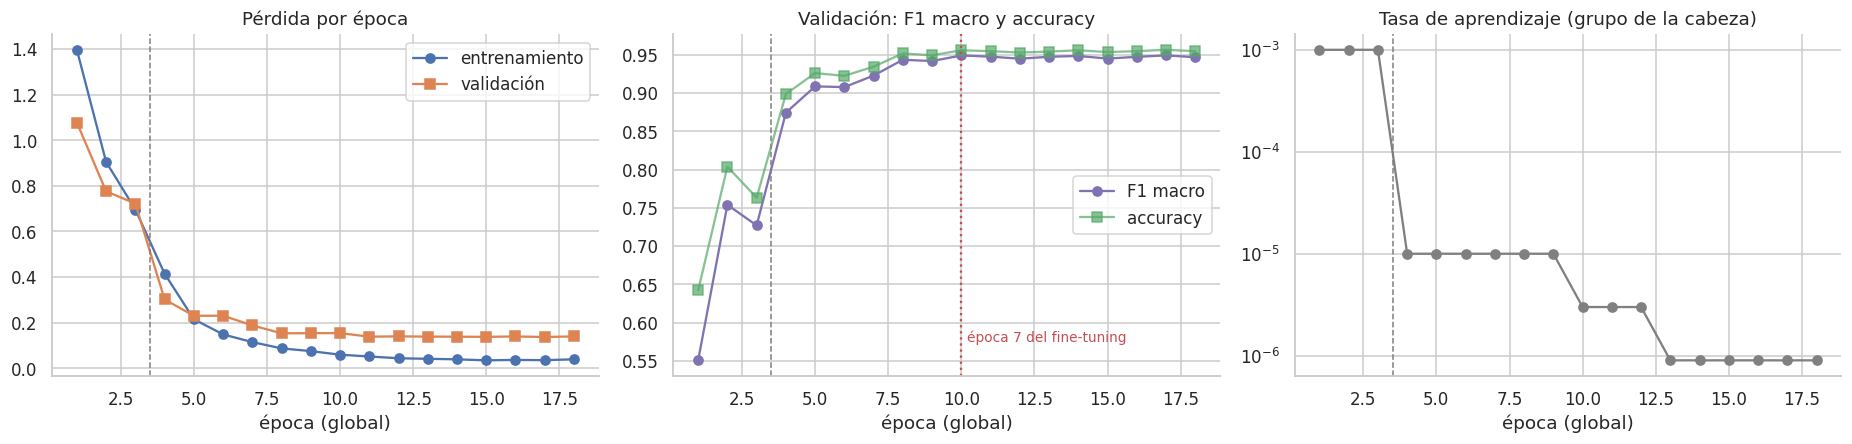

Fine-tuning: la pérdida de validación mínima está en la época 14 y el F1 queda a menos de 0,002 de su máximo desde la época 7 (de 15). Los barridos usan 6; el entrenamiento final usa hasta 10 con early stopping.


In [41]:
# 5b. curva de épocas: la configuración base entrenada sin early stopping
cfg_curva = {**BASE_CFG, 'ep_head': EP_HEAD, 'ep_fine': CURVE_EP_FINE}
r_curva = run_cached('curva_epocas', cfg_curva, TAG_SW, SW_FIT, SW_VAL, sin_early_stopping=True)
h = pd.DataFrame(r_curva['hist']); h['epoca_fine'] = h.groupby('phase').cumcount() + 1
fine = h[h.phase == 2]

# época recomendada: la primera donde el F1 de validación queda a menos de 0,002 de su máximo
if len(fine):
    f1_max = fine['val_f1'].max()
    EP_FINE_REC = int(fine[fine['val_f1'] >= f1_max - 0.002]['epoca_fine'].iloc[0])
    EP_FINE_MINLOSS = int(fine.loc[fine['val_loss'].idxmin(), 'epoca_fine'])
else:
    EP_FINE_REC = EP_FINE_MINLOSS = 0

fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
ax[0].plot(h['epoch'], h['loss'], '-o', label='entrenamiento'); ax[0].plot(h['epoch'], h['val_loss'], '-s', label='validación')
ax[0].set_title('Pérdida por época'); ax[0].set_xlabel('época (global)'); ax[0].legend()
ax[1].plot(h['epoch'], h['val_f1'], '-o', color='#8172B2', label='F1 macro'); ax[1].plot(h['epoch'], h['val_acc'], '-s', color='#55A868', alpha=.7, label='accuracy')
ax[1].set_title('Validación: F1 macro y accuracy'); ax[1].set_xlabel('época (global)'); ax[1].legend()
ax[2].semilogy(h['epoch'], h['lr'], '-o', color='gray'); ax[2].set_title('Tasa de aprendizaje (grupo de la cabeza)'); ax[2].set_xlabel('época (global)')
n1 = int((h.phase == 1).sum())
for a in ax:
    a.axvline(n1 + 0.5, color='gray', ls='--', lw=1)
if EP_FINE_REC:
    ax[1].axvline(n1 + EP_FINE_REC, color='#C44E52', ls=':', lw=1.5)
    ax[1].text(n1 + EP_FINE_REC + 0.2, ax[1].get_ylim()[0] + 0.1 * np.diff(ax[1].get_ylim())[0], f'época {EP_FINE_REC} del fine-tuning', color='#C44E52', fontsize=9)
plt.tight_layout(); plt.savefig(FIGS_DIR / 'curva_epocas.png', dpi=150); plt.show()
print(f'Fine-tuning: la pérdida de validación mínima está en la época {EP_FINE_MINLOSS} y el F1 queda a menos de 0,002 de su máximo desde la época {EP_FINE_REC} '
      f'(de {CURVE_EP_FINE}). Los barridos usan {EP_FINE}; el entrenamiento final usa hasta {FINAL_EP_FINE} con early stopping.')

## 6. Barridos de un factor a la vez

Cada fila cambia **un solo** hiperparámetro respecto a la configuración base y deja el resto igual. Todas las corridas comparten la misma semilla, los mismos datos y la misma validación (pacientes distintos a los del entrenamiento y a los del test).

**Cómo leer los resultados.** Con una sola semilla, diferencias menores que `MIN_GAIN` (por defecto 0,003 de F1 macro) son ruido de entrenamiento y no se consideran mejoras: en las gráficas es la franja gris alrededor de la línea de la configuración base. Los valores de un barrido corto (pocas épocas) favorecen LR más altas porque convergen más rápido; por eso la validación cruzada de la sección 8 vuelve a verificar la elección con más épocas.

In [42]:
# 6a. correr los barridos
filas = []
if RUN_SWEEPS:
    for factor in FACTORES_A_CORRER:
        print(f'== {factor} ==')
        for v in SWEEPS[factor]:
            cfg = {**cfg_sw, factor: v}
            r = run_cached(f'{factor}={v}', cfg, TAG_SW, SW_FIT, SW_VAL)
            filas.append(dict(factor=factor, valor_raw=v, valor=str(v), es_base=(v == cfg_sw[factor]), val_f1=r['val_f1'], val_acc=r['val_acc'],
                              val_loss=r['val_loss'], mejor_epoca=r['best_epoch'], minutos=r['secs'] / 60, hist=r['hist']))
df_sw = pd.DataFrame(filas)
if len(df_sw):
    display(df_sw.drop(columns=['valor_raw', 'hist']).round(4))
    df_sw.drop(columns=['hist']).to_csv(ABL_DIR / 'barridos.csv', index=False)

== lr_fine ==
== lr_head ==
== ep_head ==
== bs ==
== wd ==
== label_smoothing ==
== aug ==
== sched ==
== llrd ==
== unfreeze ==
== head ==
== head_dropout ==


,factor,valor,es_base,val_f1,val_acc,val_loss,mejor_epoca,minutos
0,lr_fine,1e-06,False,0.8599,0.8884,0.3429,9,4.4935
1,lr_fine,3e-06,False,0.9148,0.9290,0.2220,9,4.4655
2,lr_fine,1e-05,True,0.9414,0.9493,0.1547,9,4.3272
3,lr_fine,3e-05,False,0.9501,0.9564,0.1375,7,4.4393
4,lr_fine,0.0001,False,0.9516,0.9588,0.1520,7,4.4152
5,lr_head,0.0003,False,0.9480,0.9558,0.1642,9,4.4671
6,lr_head,0.001,True,0.9414,0.9493,0.1547,9,4.3272
7,lr_head,0.003,False,0.9455,0.9535,0.1647,9,4.4305
8,ep_head,1,False,0.9461,0.9541,0.1799,7,3.9599
9,ep_head,3,True,0.9414,0.9493,0.1547,9,4.3272


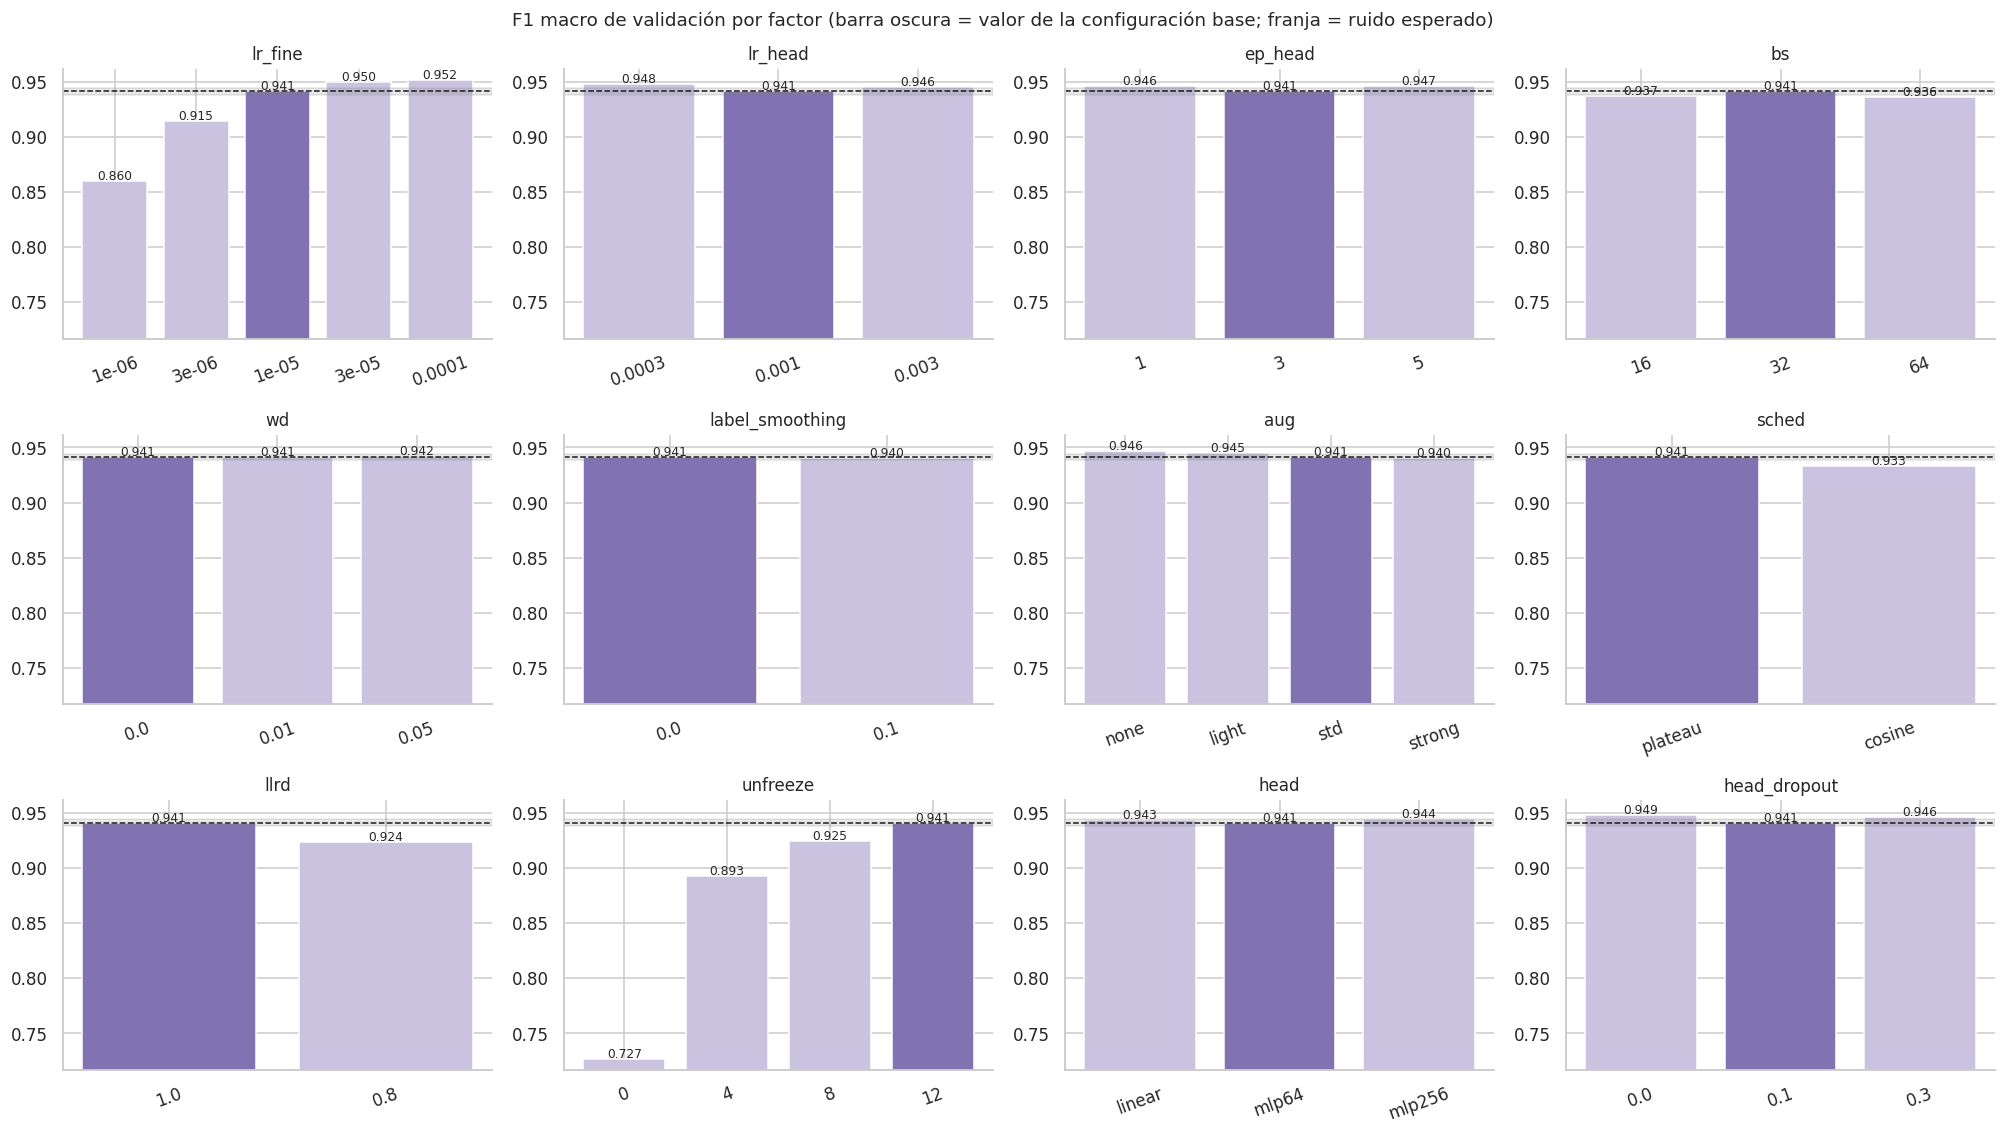

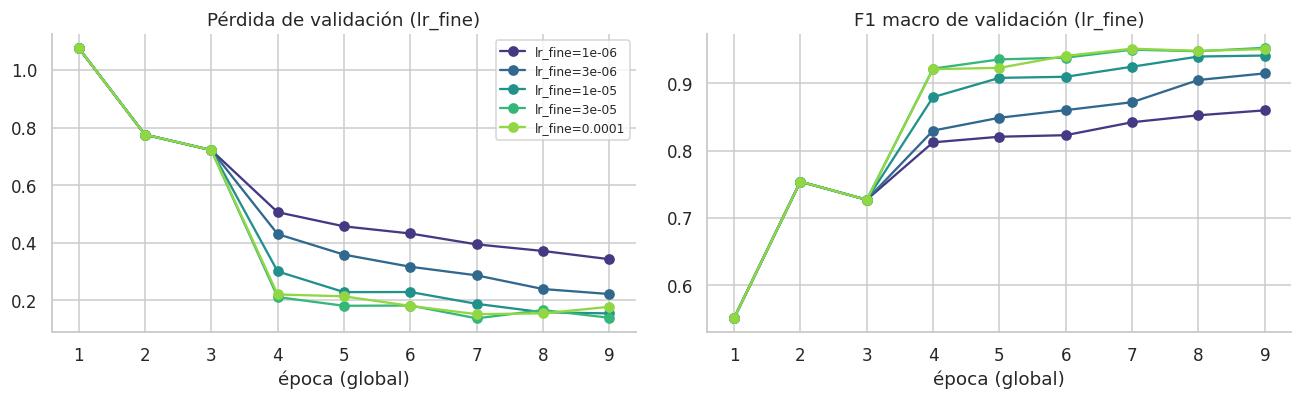

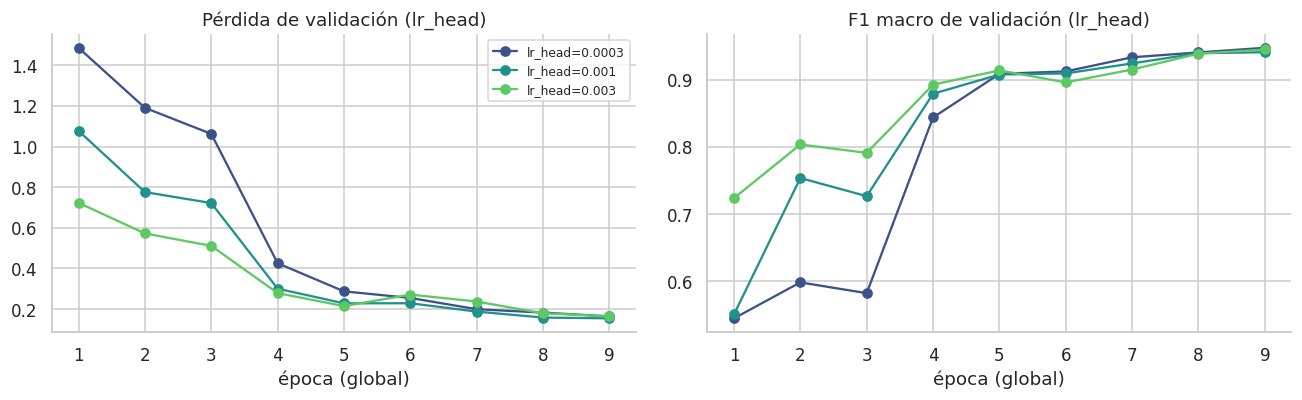

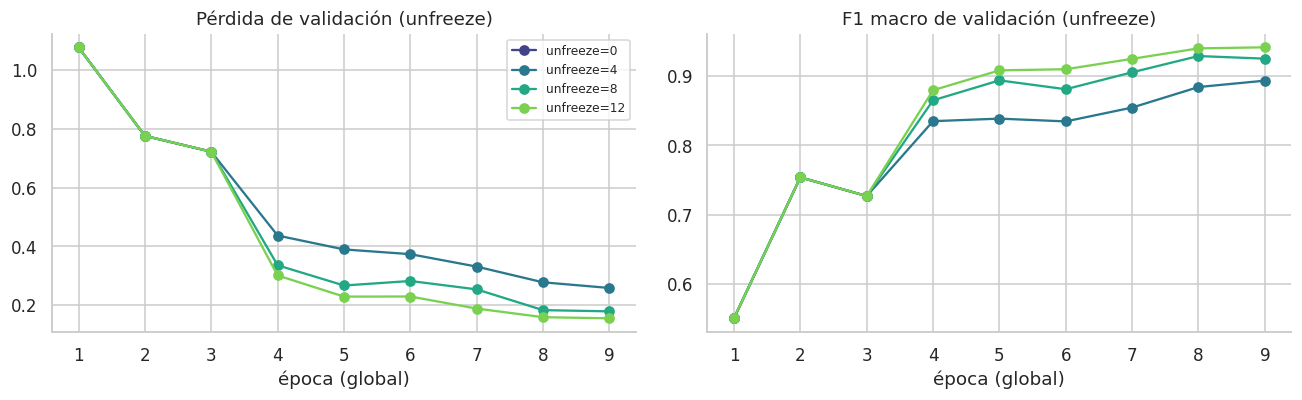

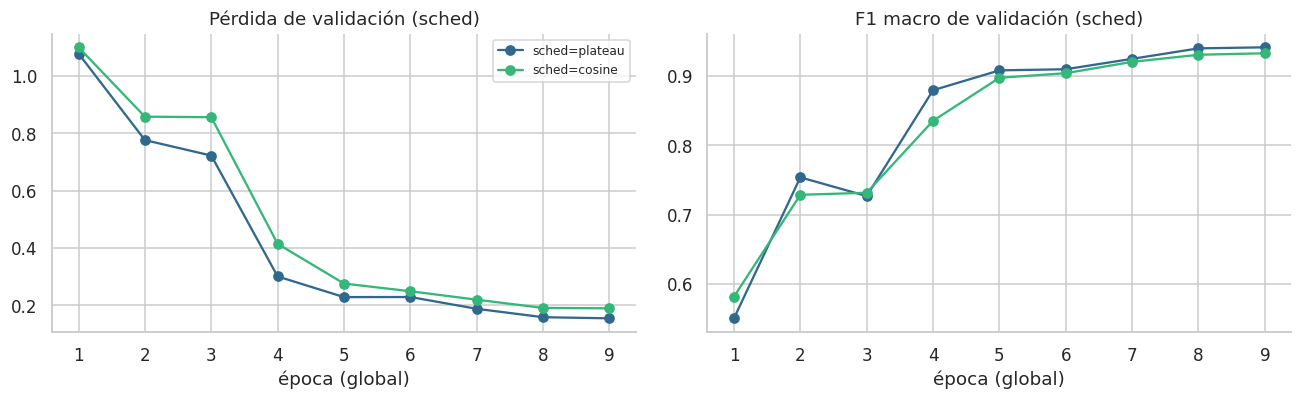

In [43]:
# 6b. gráficas de los barridos (misma escala en todos los paneles para poder comparar factores)
if len(df_sw):
    fs = list(dict.fromkeys(df_sw['factor'])); nc = 4; nr = math.ceil(len(fs) / nc)
    lo, hi = df_sw['val_f1'].min() - 0.01, min(1.0, df_sw['val_f1'].max() + 0.01)
    fig, axes = plt.subplots(nr, nc, figsize=(4.6 * nc, 3.5 * nr), squeeze=False)
    for ax, f in zip(axes.ravel(), fs):
        g = df_sw[df_sw.factor == f]
        cols = ['#8172B2' if b else '#c9c3e0' for b in g['es_base']]
        ax.bar(g['valor'], g['val_f1'], color=cols)
        ax.axhline(BASE_F1, color='k', ls='--', lw=1); ax.axhspan(BASE_F1 - MIN_GAIN, BASE_F1 + MIN_GAIN, color='gray', alpha=.18)
        for i, v in enumerate(g['val_f1']):
            ax.text(i, v + 0.001, f'{v:.3f}', ha='center', fontsize=8)
        ax.set_ylim(lo, hi); ax.set_title(f, fontsize=11); ax.tick_params(axis='x', rotation=20)
    for ax in axes.ravel()[len(fs):]:
        ax.axis('off')
    fig.suptitle('F1 macro de validación por factor (barra oscura = valor de la configuración base; franja = ruido esperado)', fontsize=12)
    plt.tight_layout(); plt.savefig(FIGS_DIR / 'barridos_f1.png', dpi=150); plt.show()

    # curvas de pérdida de validación para los factores que cambian la dinámica del entrenamiento
    for f in [x for x in ('lr_fine', 'lr_head', 'unfreeze', 'sched') if x in fs]:
        fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
        for (_, row), c in zip(df_sw[df_sw.factor == f].iterrows(), sns.color_palette('viridis', int((df_sw.factor == f).sum()))):
            hh = row['hist']; ax[0].plot(hh['epoch'], hh['val_loss'], '-o', color=c, label=f"{f}={row['valor']}"); ax[1].plot(hh['epoch'], hh['val_f1'], '-o', color=c)
        ax[0].set_title(f'Pérdida de validación ({f})'); ax[1].set_title(f'F1 macro de validación ({f})')
        for a in ax: a.set_xlabel('época (global)')
        ax[0].legend(fontsize=8); plt.tight_layout(); plt.savefig(FIGS_DIR / f'curvas_{f}.png', dpi=150); plt.show()

## 7. Mejor configuración

Se elige así, para que la decisión no dependa del ruido de una semilla:
1. De cada factor se toma el valor con mayor F1 macro de validación **solo si** supera a la configuración base en más de `MIN_GAIN`; si no, se queda el valor original.
2. Se entrena la configuración **combinada** (todos los cambios a la vez), porque los efectos no tienen por qué sumarse.
3. Opcional: una **búsqueda aleatoria** que explora combinaciones que el barrido de uno en uno no ve.
4. Se queda con la candidata de mayor F1 de validación; si ninguna supera a la base en más de `MIN_GAIN`, **se conserva la base** (y eso también es un resultado: el entrenamiento original ya estaba bien ajustado).

In [44]:
# 7a. combinación de los mejores valores de cada factor
def py(v):
    return v.item() if hasattr(v, 'item') else v

CANDIDATOS = {'BASE': (cfg_sw, r_base)}
cambios = {}
if len(df_sw):
    for f, g in df_sw.groupby('factor', sort=False):
        top = g.sort_values(['val_f1', 'val_loss'], ascending=[False, True]).iloc[0]
        if (not top['es_base']) and top['val_f1'] - BASE_F1 > MIN_GAIN:
            cambios[f] = py(top['valor_raw'])
            CANDIDATOS[f'solo {f}={cambios[f]}'] = ({**cfg_sw, f: cambios[f]}, run_cached(f'{f}={cambios[f]}', {**cfg_sw, f: cambios[f]}, TAG_SW, SW_FIT, SW_VAL))
print('Factores donde algún valor supera a la base en más de MIN_GAIN:', cambios or 'ninguno')
if len(cambios) > 1:
    cfg_comb = {**cfg_sw, **cambios}
    CANDIDATOS['COMBINADA'] = (cfg_comb, run_cached('COMBINADA', cfg_comb, TAG_SW, SW_FIT, SW_VAL))

Factores donde algún valor supera a la base en más de MIN_GAIN: {'lr_fine': 0.0001, 'lr_head': 0.0003, 'ep_head': 5, 'aug': 'none', 'head_dropout': 0.0}


In [45]:
# 7b. búsqueda aleatoria (opcional): explora combinaciones de varios factores a la vez
if RUN_RANDOM and N_RANDOM > 0:
    rng = np.random.default_rng(SEED)
    for i in range(N_RANDOM):
        cfg = {**cfg_sw,
               'lr_fine': float(10 ** rng.uniform(-5.7, -4.0)), 'lr_head': float(10 ** rng.uniform(-3.5, -2.5)),
               'wd': float(rng.choice([0.0, 0.01, 0.05])), 'bs': int(rng.choice([16, 32, 64])),
               'label_smoothing': float(rng.choice([0.0, 0.1])), 'sched': str(rng.choice(['plateau', 'cosine'])),
               'llrd': float(rng.choice([1.0, 0.9, 0.8])), 'aug': str(rng.choice(['light', 'std', 'strong']))}
        cfg['lr_fine'], cfg['lr_head'] = float(f"{cfg['lr_fine']:.2e}"), float(f"{cfg['lr_head']:.2e}")
        CANDIDATOS[f'aleatoria_{i}'] = (cfg, run_cached(f'aleatoria_{i}', cfg, TAG_SW, SW_FIT, SW_VAL))

In [46]:
# 7c. decisión final de configuración
tabla = pd.DataFrame([{'candidata': n, 'val_f1': r['val_f1'], 'val_acc': r['val_acc'], 'val_loss': r['val_loss'], 'mejor_epoca': r['best_epoch'],
                       'minutos': r['secs'] / 60} for n, (c, r) in CANDIDATOS.items()]).sort_values(['val_f1', 'val_loss'], ascending=[False, True])
display(tabla.round(4))
mejor_nombre = tabla.iloc[0]['candidata']
if tabla.iloc[0]['val_f1'] - BASE_F1 <= MIN_GAIN:
    mejor_nombre = 'BASE'
    print(f'Ninguna candidata supera a la base en más de {MIN_GAIN}: se conserva la configuración original.')
CFG_MEJOR = dict(CANDIDATOS[mejor_nombre][0])
dif = {k: (BASE_CFG[k], CFG_MEJOR[k]) for k in CFG_MEJOR if k in BASE_CFG and CFG_MEJOR[k] != BASE_CFG[k] and k not in ('ep_head', 'ep_fine')}
CONCL['cambios'] = dif
print('Mejor candidata:', mejor_nombre, '| cambios respecto al notebook principal (original -> nuevo):', dif or 'ninguno')
(ABL_DIR / 'config_mejor_barrido.json').write_text(json.dumps({'candidata': mejor_nombre, 'cfg': CFG_MEJOR, 'val_f1': CANDIDATOS[mejor_nombre][1]['val_f1']}, default=_jd, indent=1))

,candidata,val_f1,val_acc,val_loss,mejor_epoca,minutos
6,COMBINADA,0.9578,0.9642,0.1171,7,4.2639
7,aleatoria_0,0.9573,0.9618,0.1587,9,4.3369
1,solo lr_fine=0.0001,0.9516,0.9588,0.1520,7,4.4152
5,solo head_dropout=0.0,0.9486,0.9547,0.1483,9,4.4557
2,solo lr_head=0.0003,0.9480,0.9558,0.1642,9,4.4671
3,solo ep_head=5,0.9465,0.9547,0.1538,11,4.9448
4,solo aug=none,0.9464,0.9564,0.1454,9,4.4025
0,BASE,0.9414,0.9493,0.1547,9,4.3272
8,aleatoria_1,0.9345,0.9469,0.3022,7,4.3517
11,aleatoria_4,0.9285,0.9415,0.2451,9,4.3614


Mejor candidata: COMBINADA | cambios respecto al notebook principal (original -> nuevo): {'lr_head': (0.001, 0.0003), 'lr_fine': (1e-05, 0.0001), 'aug': ('std', 'none'), 'head_dropout': (0.1, 0.0)}


346

## 7 bis. Análisis de componentes: qué pasa si se quita cada pieza

Partiendo de la mejor configuración, se **quita un componente a la vez** y se mide cuánto cae el F1 de validación. Se repite con varias semillas (`ABL_SEEDS`) porque con una sola un efecto pequeño no se distingue del ruido.

| Variante | Qué se quita | Cómo se compara |
|---|---|---|
| sin pesos de clase | la ponderación por clase de la pérdida | mismo presupuesto de épocas |
| sin fase 1 (cabeza) | el calentamiento de la cabeza con el ViT congelado (`ep_head=0`) | pierde esas épocas |
| sin fine-tuning | el ajuste del ViT: solo se entrena la cabeza | se le dan **todas** las épocas (cabeza + fine-tuning) para no castigarla |
| sin preentrenamiento | los pesos de ImageNet-21k (inicialización aleatoria, `lr_fine=3e-4`, sin fase 1) | mismas épocas totales; es una cota inferior, un ViT desde cero necesita muchas más |

Los barridos de la sección 6 ya cubren el resto de componentes (aumentos, scheduler, cabeza, LLRD, etc.); la celda 7e los ordena por cuánto mueven el F1.

== completo (mejor config.) ==
  completo (mejor config.)|s43       val_f1 0.9573 | val_acc 0.9648 | val_loss 0.1573 | mejor época 11/11 | 4.5 min
  completo (mejor config.)|s44       val_f1 0.9561 | val_acc 0.9624 | val_loss 0.1528 | mejor época 10/11 | 4.5 min
== sin pesos de clase ==
  sin pesos de clase|s42             val_f1 0.9597 | val_acc 0.9660 | val_loss 0.1390 | mejor época 8/11 | 4.5 min
  sin pesos de clase|s43             val_f1 0.9612 | val_acc 0.9666 | val_loss 0.1357 | mejor época 9/11 | 4.5 min
  sin pesos de clase|s44             val_f1 0.9553 | val_acc 0.9618 | val_loss 0.1450 | mejor época 11/11 | 4.5 min
== sin fase 1 (cabeza) ==
  sin fase 1 (cabeza)|s42            val_f1 0.9562 | val_acc 0.9660 | val_loss 0.1409 | mejor época 4/6 | 3.4 min
  sin fase 1 (cabeza)|s43            val_f1 0.9543 | val_acc 0.9618 | val_loss 0.1476 | mejor época 6/6 | 3.4 min
  sin fase 1 (cabeza)|s44            val_f1 0.9517 | val_acc 0.9612 | val_loss 0.1686 | mejor época 4/6 | 3.4 mi

,F1 media,desv. (semillas),Δ vs completo,peor que completo en
variante,,,,
completo (mejor config.),0.9571,0.0009,0.0000,0/3 semillas
sin pesos de clase,0.9587,0.0031,0.0017,1/3 semillas
sin fase 1 (cabeza),0.9541,0.0023,-0.0030,3/3 semillas
sin fine-tuning (solo cabeza),0.7941,0.0107,-0.1629,3/3 semillas
sin preentrenamiento (aleatorio),0.1777,0.1847,-0.7794,3/3 semillas


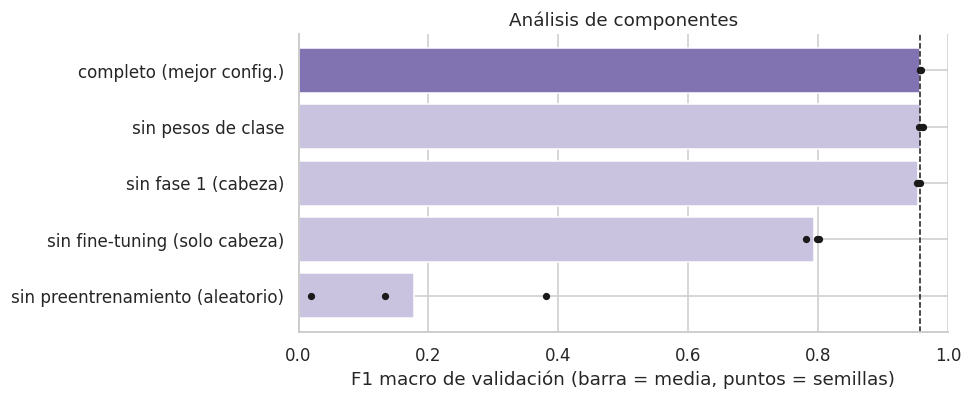

In [47]:
# 7d. quitar un componente a la vez (varias semillas, mismo protocolo de los barridos)
COMPONENTES = {'completo (mejor config.)': {},
               'sin pesos de clase': {'class_weights': False},
               'sin fase 1 (cabeza)': {'ep_head': 0},
               'sin fine-tuning (solo cabeza)': {'ep_fine': 0, 'ep_head': EP_HEAD + EP_FINE},
               'sin preentrenamiento (aleatorio)': {'pretrained': False, 'ep_head': 0, 'ep_fine': EP_HEAD + EP_FINE, 'lr_fine': 3e-4}}
comp_filas = []
if RUN_COMPONENTES:
    for nombre, cambio in COMPONENTES.items():
        print(f'== {nombre} ==')
        for s in ABL_SEEDS:
            r = run_cached(f'{nombre}|s{s}', {**CFG_MEJOR, **cambio}, TAG_SW, SW_FIT, SW_VAL, seed=s)
            comp_filas.append(dict(variante=nombre, semilla=s, val_f1=r['val_f1'], val_acc=r['val_acc'], val_loss=r['val_loss']))
if comp_filas:
    cdf = pd.DataFrame(comp_filas); cdf.to_csv(ABL_DIR / 'componentes_por_semilla.csv', index=False)
    piv = cdf.pivot(index='semilla', columns='variante', values='val_f1')[list(COMPONENTES)]
    ref_c = piv['completo (mejor config.)']
    tab = pd.DataFrame({'F1 media': piv.mean(), 'desv. (semillas)': piv.std(ddof=1) if len(piv) > 1 else np.nan,
                        'Δ vs completo': (piv.sub(ref_c, axis=0)).mean(),
                        'peor que completo en': (piv.sub(ref_c, axis=0) < 0).sum().astype(str) + f'/{len(piv)} semillas'})
    display(tab.round(4)); tab.to_csv(ABL_DIR / 'componentes.csv')
    RUIDO_SEM = float(piv['completo (mejor config.)'].std(ddof=1)) if len(piv) > 1 else MIN_GAIN
    CONCL['componentes'] = dict(tab=tab, ruido=RUIDO_SEM)
    fig, ax = plt.subplots(figsize=(9, 3.8)); orden_c = list(COMPONENTES)
    ax.barh(range(len(orden_c)), piv.mean().values, color=['#8172B2'] + ['#c9c3e0'] * (len(orden_c) - 1))
    for k, n in enumerate(orden_c):
        ax.scatter(piv[n].values, np.full(len(piv), k), color='k', s=14, zorder=3)
    ax.set_yticks(range(len(orden_c))); ax.set_yticklabels(orden_c); ax.invert_yaxis()
    ax.set_xlim(max(0, piv.values.min() - .05), 1.0); ax.set_xlabel('F1 macro de validación (barra = media, puntos = semillas)')
    ax.axvline(piv['completo (mejor config.)'].mean(), color='k', ls='--', lw=1); ax.set_title('Análisis de componentes')
    plt.tight_layout(); plt.savefig(FIGS_DIR / 'componentes.png', dpi=150); plt.show()

,ganancia máx. vs base,pérdida máx. vs base,rango,¿sobre el ruido?
factor,,,,
unfreeze,0.0000,-0.2145,0.2145,sí
lr_fine,0.0102,-0.0815,0.0917,sí
llrd,0.0000,-0.0178,0.0178,sí
sched,0.0000,-0.0086,0.0086,sí
head_dropout,0.0073,0.0000,0.0073,sí
lr_head,0.0066,0.0000,0.0066,sí
aug,0.0050,-0.0009,0.0059,sí
bs,0.0000,-0.0055,0.0055,sí
ep_head,0.0051,0.0000,0.0051,sí


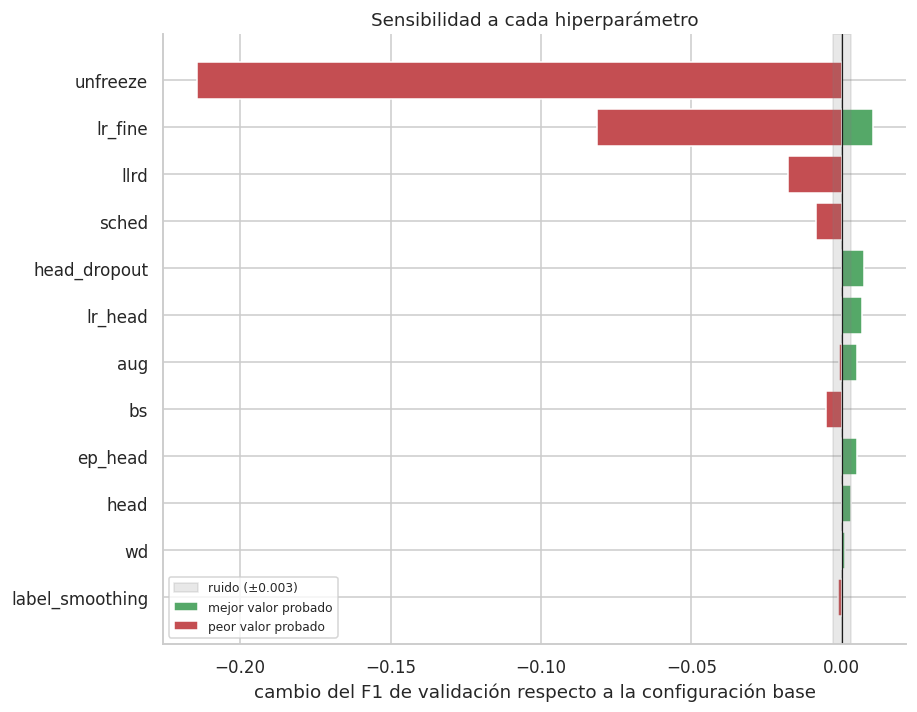

El ranking depende de qué valores se probaron (los extremos como unfreeze=0 o lr_fine=1e-6 dominan por ser extremos) y es de una semilla; el ruido se estima con la desviación entre semillas de 7d (±0.003).


In [48]:
# 7e. qué hiperparámetros mueven más el F1 (a partir de los barridos de la sección 6)
if len(df_sw):
    g = df_sw.groupby('factor', sort=False)['val_f1']
    sens = pd.DataFrame({'ganancia máx. vs base': g.max() - BASE_F1, 'pérdida máx. vs base': g.min() - BASE_F1, 'rango': g.max() - g.min()}).sort_values('rango', ascending=False)
    ruido = CONCL.get('componentes', {}).get('ruido', MIN_GAIN); umbral = max(MIN_GAIN, 2 * ruido)
    sens['¿sobre el ruido?'] = np.where(sens['rango'] > umbral, 'sí', 'no (dentro del ruido)')
    display(sens.round(4)); sens.to_csv(ABL_DIR / 'sensibilidad_hiperparametros.csv')
    fig, ax = plt.subplots(figsize=(8.5, 0.42 * len(sens) + 1.6)); y_ = np.arange(len(sens))
    ax.barh(y_, sens['ganancia máx. vs base'], color='#55A868', label='mejor valor probado'); ax.barh(y_, sens['pérdida máx. vs base'], color='#C44E52', label='peor valor probado')
    ax.axvspan(-umbral, umbral, color='gray', alpha=.18, label=f'ruido (±{umbral:.3f})'); ax.axvline(0, color='k', lw=.8)
    ax.set_yticks(y_); ax.set_yticklabels(sens.index); ax.invert_yaxis(); ax.set_xlabel('cambio del F1 de validación respecto a la configuración base'); ax.legend(fontsize=8)
    ax.set_title('Sensibilidad a cada hiperparámetro'); plt.tight_layout(); plt.savefig(FIGS_DIR / 'sensibilidad_hiperparametros.png', dpi=150); plt.show()
    print(f'El ranking depende de qué valores se probaron (los extremos como unfreeze=0 o lr_fine=1e-6 dominan por ser extremos) y es de una semilla; el ruido se estima con la desviación entre semillas de 7d (±{umbral:.3f}).')
    CONCL['sens'] = sens

## 8. Validación cruzada por paciente

Se compara la configuración original contra la mejor, con **los mismos folds** (`StratifiedGroupKFold` por paciente sobre el train: ningún paciente cae en dos folds). En cada fold se entrena con el resto (con una validación interna para early stopping) y se evalúa en el fold retenido. Como cada imagen del train se evalúa exactamente una vez, también se obtienen predicciones fuera de muestra (OOF) de todo el train para pruebas estadísticas.

Cada fold se guarda al terminar. Dos advertencias: con pocos folds la potencia estadística es baja (la prueba de Wilcoxon con 3 folds nunca puede dar p < 0,25), y los pacientes del split de validación del barrido ya intervinieron en la elección de la configuración, así que la CV tiene un sesgo optimista pequeño a favor de la configuración elegida. El test sigue intacto.

In [49]:
# 8a. validación cruzada por paciente: configuración original vs mejor
CV_CONFIGS = {'original': {**BASE_CFG, 'ep_head': CV_EP_HEAD, 'ep_fine': CV_EP_FINE},
              'mejor':    {**CFG_MEJOR, 'ep_head': CV_EP_HEAD, 'ep_fine': CV_EP_FINE}}
if CV_CONFIGS['original'] == CV_CONFIGS['mejor']:
    print('La mejor configuración es la original: la CV solo la evalúa una vez.'); CV_CONFIGS.pop('mejor')

folds = list(StratifiedGroupKFold(n_splits=CV_K, shuffle=True, random_state=SEED).split(POOL, y_pool, groups=pat_pool))
CV_RES, OOF = {n: [] for n in CV_CONFIGS}, {n: np.full(len(POOL), -1) for n in CV_CONFIGS}
if RUN_CV:
    for k, (a, b) in enumerate(folds):
        fit_k = subsample_patients(a, CV_FRAC, SEED + k)
        fit_k, val_k = split_val(fit_k, SEED + k)
        tag = f'cv|K={CV_K}|frac={CV_FRAC}|fold={k}'
        print(f'== fold {k+1}/{CV_K}: entrenamiento {len(fit_k)} | validación interna {len(val_k)} | fold retenido {len(b)} ==')
        for nombre, cfg in CV_CONFIGS.items():
            r = run_cached(f'{nombre}|fold{k+1}', cfg, tag, fit_k, val_k, eval_idx=b)
            CV_RES[nombre].append(r); OOF[nombre][b] = r['ev_pred']
            print(f"    -> fold retenido: F1 {r['ev_f1']:.4f} | acc {r['ev_acc']:.4f}")

== fold 1/5: entrenamiento 2977 | validación interna 890 | fold retenido 1676 ==
    -> fold retenido: F1 0.9345 | acc 0.9457
    -> fold retenido: F1 0.9567 | acc 0.9630
== fold 2/5: entrenamiento 3249 | validación interna 872 | fold retenido 1567 ==
    -> fold retenido: F1 0.9570 | acc 0.9617
    -> fold retenido: F1 0.9677 | acc 0.9719
== fold 3/5: entrenamiento 3019 | validación interna 796 | fold retenido 1877 ==
    -> fold retenido: F1 0.9494 | acc 0.9558
    -> fold retenido: F1 0.9565 | acc 0.9643
== fold 4/5: entrenamiento 3425 | validación interna 845 | fold retenido 1622 ==
    -> fold retenido: F1 0.9502 | acc 0.9581
    -> fold retenido: F1 0.9652 | acc 0.9704
== fold 5/5: entrenamiento 3346 | validación interna 695 | fold retenido 1810 ==
    -> fold retenido: F1 0.9514 | acc 0.9552
    -> fold retenido: F1 0.9676 | acc 0.9718


F1 macro         Accuracy         Pérdida        
             mean     std     mean     std    mean     std
config                                                    
mejor      0.9628  0.0057   0.9683  0.0043  0.1265  0.0255
original   0.9485  0.0083   0.9553  0.0059  0.1332  0.0144

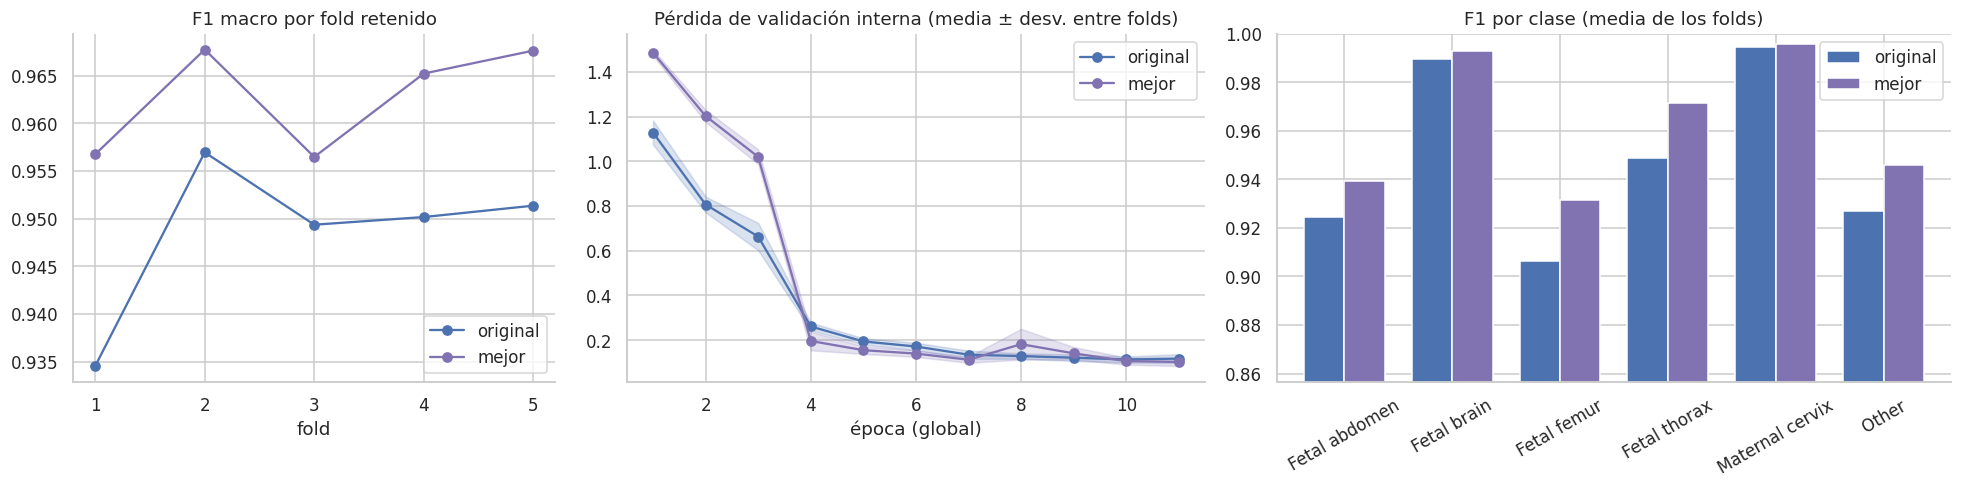

In [50]:
# 8b. resultados de la validación cruzada
if RUN_CV and all(len(v) == CV_K for v in CV_RES.values()):
    cv_df = pd.DataFrame([{'config': n, 'fold': k + 1, 'F1 macro': r['ev_f1'], 'Accuracy': r['ev_acc'], 'Pérdida': r['ev_loss']}
                          for n, rs in CV_RES.items() for k, r in enumerate(rs)])
    resumen = cv_df.groupby('config')[['F1 macro', 'Accuracy', 'Pérdida']].agg(['mean', 'std']).round(4)
    display(resumen); cv_df.to_csv(ABL_DIR / 'cv_por_fold.csv', index=False)

    fig, ax = plt.subplots(1, 3, figsize=(18, 4.6), gridspec_kw={'width_ratios': [1, 1.2, 1.4]})
    cols = {'original': '#4C72B0', 'mejor': '#8172B2'}
    for n in CV_CONFIGS:
        ax[0].plot(np.arange(CV_K) + 1, [r['ev_f1'] for r in CV_RES[n]], '-o', color=cols[n], label=n)
    ax[0].set_title('F1 macro por fold retenido'); ax[0].set_xlabel('fold'); ax[0].set_xticks(np.arange(CV_K) + 1); ax[0].legend()
    for n in CV_CONFIGS:       # curvas de aprendizaje: media y desviación entre folds (los folds con early stopping más corto quedan en NaN)
        L = max(len(r['hist']['val_loss']) for r in CV_RES[n]); M = np.full((CV_K, L), np.nan)
        for k, r in enumerate(CV_RES[n]): M[k, :len(r['hist']['val_loss'])] = r['hist']['val_loss']
        mu, sd = np.nanmean(M, 0), np.nanstd(M, 0); e = np.arange(1, L + 1)
        ax[1].plot(e, mu, '-o', color=cols[n], label=n); ax[1].fill_between(e, mu - sd, mu + sd, color=cols[n], alpha=.2)
    ax[1].set_title('Pérdida de validación interna (media ± desv. entre folds)'); ax[1].set_xlabel('época (global)'); ax[1].legend()
    f1c = pd.DataFrame({n: np.mean([r['ev_f1_clase'] for r in CV_RES[n]], 0) for n in CV_CONFIGS}, index=classes)
    f1c.plot.bar(ax=ax[2], color=[cols[n] for n in CV_CONFIGS], width=.75); ax[2].set_ylim(max(0, f1c.values.min() - .05), 1.0)
    ax[2].set_title('F1 por clase (media de los folds)'); ax[2].tick_params(axis='x', rotation=30)
    plt.tight_layout(); plt.savefig(FIGS_DIR / 'cv_resultados.png', dpi=150); plt.show()

In [51]:
# 8c. ¿la diferencia entre configuraciones es real? pruebas pareadas por fold y con las predicciones fuera de muestra
def macro_f1_fast(y, p, K=num_classes):
    cm = np.bincount(y * K + p, minlength=K * K).reshape(K, K)
    tp = np.diag(cm).astype(float); fp = cm.sum(0) - tp; fn = cm.sum(1) - tp
    den = 2 * tp + fp + fn
    return float(np.mean(np.where(den > 0, 2 * tp / np.maximum(den, 1), 0.0)))

def boot_idx(pacientes, n_boot, seed=SEED):
    # se remuestrean pacientes completos (las imágenes de un paciente no son independientes)
    codes, uniq = pd.factorize(pacientes); grupos = [np.where(codes == g)[0] for g in range(len(uniq))]
    rng = np.random.default_rng(seed)
    return [np.concatenate([grupos[g] for g in rng.integers(0, len(grupos), len(grupos))]) for _ in range(n_boot)]

if RUN_CV and 'mejor' in CV_CONFIGS and len(CV_RES['mejor']) == CV_K:
    a = np.array([r['ev_f1'] for r in CV_RES['original']]); b = np.array([r['ev_f1'] for r in CV_RES['mejor']]); d = b - a
    print(f'Diferencia de F1 (mejor - original) por fold: {np.round(d, 4)} | media {d.mean():+.4f} ± {d.std(ddof=1) if CV_K > 1 else float("nan"):.4f} | mejor en {(d > 0).sum()}/{CV_K} folds')
    if CV_K >= 3:
        print(f'  t pareada: p = {stats.ttest_rel(b, a).pvalue:.3f} | Wilcoxon: p = {stats.wilcoxon(b, a).pvalue:.3f}')
    yo, po, pm = y_pool, OOF['original'], OOF['mejor']
    assert (po >= 0).all() and (pm >= 0).all()
    bi = boot_idx(pat_pool, N_BOOT)
    dif = np.array([macro_f1_fast(yo[i], pm[i]) - macro_f1_fast(yo[i], po[i]) for i in bi])
    lo, hi = np.percentile(dif, [2.5, 97.5])
    b01 = int(((po == yo) & (pm != yo)).sum()); c01 = int(((po != yo) & (pm == yo)).sum())
    pmc = stats.binomtest(min(b01, c01), b01 + c01, 0.5).pvalue if b01 + c01 else 1.0
    print(f'Predicciones fuera de muestra (todo el train, {len(yo)} imágenes): F1 original {macro_f1_fast(yo, po):.4f} | F1 mejor {macro_f1_fast(yo, pm):.4f}')
    CONCL['cv'] = dict(K=CV_K, dmean=float(d.mean()), dsd=float(d.std(ddof=1)), mejor_en=int((d > 0).sum()), oof_d=float(macro_f1_fast(yo, pm) - macro_f1_fast(yo, po)), oof_lo=float(lo), oof_hi=float(hi), mcnemar_p=float(pmc),
                       f1_orig=float(a.mean()), f1_mejor=float(b.mean()))
    print(f'  diferencia de F1 {macro_f1_fast(yo, pm) - macro_f1_fast(yo, po):+.4f}, IC 95 % por pacientes [{lo:+.4f}, {hi:+.4f}] '
          f'({"no incluye" if lo > 0 or hi < 0 else "incluye"} el 0) | McNemar exacto: la mejor acierta donde la original falla {c01} veces y al revés {b01} veces, p = {pmc:.3f}')

Diferencia de F1 (mejor - original) por fold: [0.0222 0.0108 0.0071 0.015  0.0163] | media +0.0143 ± 0.0057 | mejor en 5/5 folds
  t pareada: p = 0.005 | Wilcoxon: p = 0.062
Predicciones fuera de muestra (todo el train, 8552 imágenes): F1 original 0.9490 | F1 mejor 0.9631
  diferencia de F1 +0.0141, IC 95 % por pacientes [+0.0091, +0.0192] (no incluye el 0) | McNemar exacto: la mejor acierta donde la original falla 198 veces y al revés 87 veces, p = 0.000


## 9. Entrenamiento final, evaluación en test y guardado del mejor modelo

Aquí se entrena con **todo el train** (menos una validación por paciente para el early stopping) usando la mejor configuración, y se evalúa en el test **una sola vez**. Para una comparación justa también se reentrena la configuración original en exactamente las mismas condiciones (`ENTRENAR_BASELINE_FINAL`) y, si existe, se evalúa el `ViT_v3.pt` del notebook principal.

El archivo guardado (`ViT_B16_mejor_config.pt`) contiene los pesos, la configuración, las clases y las métricas; se carga con `cargar_vit(...)` (definida en la sección 4).

In [52]:
# 9a. entrenamiento final y evaluación en test
def evaluar_test(model):
    probs = predict_probs(model, Xte); pred = probs.argmax(1)
    return probs, pred, classification_report(y_te, pred, target_names=classes, output_dict=True, zero_division=0)

FINAL = {}                                         # nombre -> dict con modelo (en CPU solo el state_dict), probs, métricas
fit_f, val_f = split_val(POOL, SEED, n_splits=FINAL_VAL_SPLITS)
print(f'Entrenamiento final: {len(fit_f)} imágenes | validación {len(val_f)} | test {len(y_te)}')

def entrenar_final(nombre, cfg, seed):
    print(f'== {nombre} (semilla {seed}) ==')
    model, hist, secs = train_vit(cfg, Xpool[fit_f], y_pool[fit_f], Xpool[val_f], y_pool[val_f], seed, verbose=True)
    mv = metricas(predict_probs(model, Xpool[val_f]), y_pool[val_f])
    probs, pred, rep = evaluar_test(model)
    sd = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    del model; gc.collect()
    if device == 'cuda': torch.cuda.empty_cache()
    print(f'   val F1 {mv["f1"]:.4f} | test acc {rep["accuracy"]:.4f} | test F1 macro {rep["macro avg"]["f1-score"]:.4f} | {secs/60:.1f} min')
    return dict(cfg=cfg, seed=seed, hist=hist, secs=secs, val=mv, probs=probs, pred=pred, rep=rep, state_dict=sd)

if RUN_FINAL:
    cfg_final = {**CFG_MEJOR, 'ep_head': FINAL_EP_HEAD, 'ep_fine': FINAL_EP_FINE}
    corridas = [entrenar_final('mejor', cfg_final, s) for s in FINAL_SEEDS]
    FINAL['mejor'] = max(corridas, key=lambda r: r['val']['f1'])         # se elige por validación, nunca por test
    if len(corridas) > 1:
        t = [r['rep']['macro avg']['f1-score'] for r in corridas]
        print(f'Entre semillas, F1 macro en test: {np.round(t, 4)} (media {np.mean(t):.4f} ± {np.std(t, ddof=1):.4f})')
    if ENTRENAR_BASELINE_FINAL:
        FINAL['original'] = entrenar_final('original', {**BASE_CFG, 'ep_head': FINAL_EP_HEAD, 'ep_fine': FINAL_EP_FINE}, FINAL_SEEDS[0])

Entrenamiento final: 7313 imágenes | validación 1239 | test 2291
== mejor (semilla 42) ==
[fase 1] época 1/3 | loss 1.4436 | val_loss 1.1038 | val_f1 0.6152
[fase 1] época 2/3 | loss 0.9606 | val_loss 0.7752 | val_f1 0.7379
[fase 1] época 3/3 | loss 0.7342 | val_loss 0.6300 | val_f1 0.7769
[fase 2] época 1/10 | loss 0.2113 | val_loss 0.1222 | val_f1 0.9522
[fase 2] época 2/10 | loss 0.0587 | val_loss 0.1108 | val_f1 0.9636
[fase 2] época 3/10 | loss 0.0283 | val_loss 0.1442 | val_f1 0.9666
[fase 2] época 4/10 | loss 0.0097 | val_loss 0.1922 | val_f1 0.9433
[fase 2] época 5/10 | loss 0.0058 | val_loss 0.1419 | val_f1 0.9669
   val F1 0.9636 | test acc 0.9742 | test F1 macro 0.9712 | 6.5 min
== original (semilla 42) ==
[fase 1] época 1/3 | loss 1.1266 | val_loss 0.6784 | val_f1 0.6899
[fase 1] época 2/3 | loss 0.6465 | val_loss 0.4853 | val_f1 0.7956
[fase 1] época 3/3 | loss 0.5019 | val_loss 0.4054 | val_f1 0.8508
[fase 2] época 1/10 | loss 0.2658 | val_loss 0.2292 | val_f1 0.9130
[fas

In [53]:
# 9b. guardar el mejor modelo (pesos + configuración + clases + métricas)
if RUN_FINAL:
    m = FINAL['mejor']
    ckpt = {'state_dict': m['state_dict'], 'cfg': m['cfg'], 'classes': list(classes), 'vit_ckpt': VIT_CKPT, 'img_size': IMG_SIZE,
            'normalizacion': {'media': 0.5, 'desv': 0.5, 'nota': 'x/255 y luego (x-0.5)/0.5'}, 'seed': m['seed'],
            'val': m['val'], 'test': {'accuracy': float(m['rep']['accuracy']), 'f1_macro': float(m['rep']['macro avg']['f1-score']),
                                       'f1_por_clase': {c: float(m['rep'][c]['f1-score']) for c in classes}},
            'modo_ablacion': MODO}
    if CKPT_PATH.exists():
        shutil.copy(CKPT_PATH, str(CKPT_PATH) + '.bak')
    torch.save(ckpt, CKPT_PATH)
    (ABL_DIR / 'ViT_B16_mejor_config.json').write_text(json.dumps({k: v for k, v in ckpt.items() if k != 'state_dict'}, indent=1, default=_jd))
    print('Modelo guardado en', CKPT_PATH, f'({CKPT_PATH.stat().st_size / 1e6:.0f} MB)')
    print('Configuración:', json.dumps(ckpt['cfg']))
    # prueba de ida y vuelta: el archivo guardado debe dar las mismas predicciones
    mm, _ = cargar_vit(CKPT_PATH)
    chk = predict_probs(mm, Xte[:64]).argmax(1)
    print('Recarga del archivo coincide con el modelo entrenado:', bool((chk == m['pred'][:64]).mean() > 0.97))
    del mm; gc.collect()
else:
    print('RUN_FINAL=False: se usará el modelo ya guardado en', CKPT_PATH if CKPT_PATH.exists() else '(no existe todavía)')

Modelo guardado en /content/drive/MyDrive/IA2/proyecto_IA2/ablacion_vit/ViT_B16_mejor_config.pt (343 MB)
Configuración: {"lr_head": 0.0003, "lr_fine": 0.0001, "ep_head": 3, "ep_fine": 10, "bs": 32, "wd": 0.0, "label_smoothing": 0.0, "aug": "none", "sched": "plateau", "llrd": 1.0, "unfreeze": 12, "head": "mlp64", "head_dropout": 0.0, "pat_head": 2, "pat_fine": 3}
Recarga del archivo coincide con el modelo entrenado: True


,Accuracy,IC95 acc,F1 macro,IC95 F1
Modelo,,,,
mejor,0.9742,"[0.968, 0.980]",0.9712,"[0.963, 0.978]"
original,0.9734,"[0.966, 0.980]",0.9707,"[0.962, 0.979]"
ViT_v3 (notebook principal),0.9686,"[0.961, 0.976]",0.9643,"[0.955, 0.973]"


Test, mejor - original: ΔF1 macro = +0.0005, IC 95 % por pacientes [-0.0065, +0.0080] | McNemar exacto: 27 aciertos solo de la mejor, 25 solo de la original, p = 0.890
Si el IC incluye el 0, la diferencia no es concluyente con este test; en ese caso conviene decirlo así en el informe.

Reporte por clase de la mejor configuración:
                 precision    recall  f1-score   support

  Fetal abdomen      0.949     0.974     0.961       152
    Fetal brain      0.986     0.997     0.991       630
    Fetal femur      0.921     0.964     0.942       194
   Fetal thorax      0.960     0.994     0.977       339
Maternal cervix      0.993     0.996     0.994       267
          Other      0.985     0.939     0.962       709

       accuracy                          0.974      2291
      macro avg      0.966     0.977     0.971      2291
   weighted avg      0.975     0.974     0.974      2291



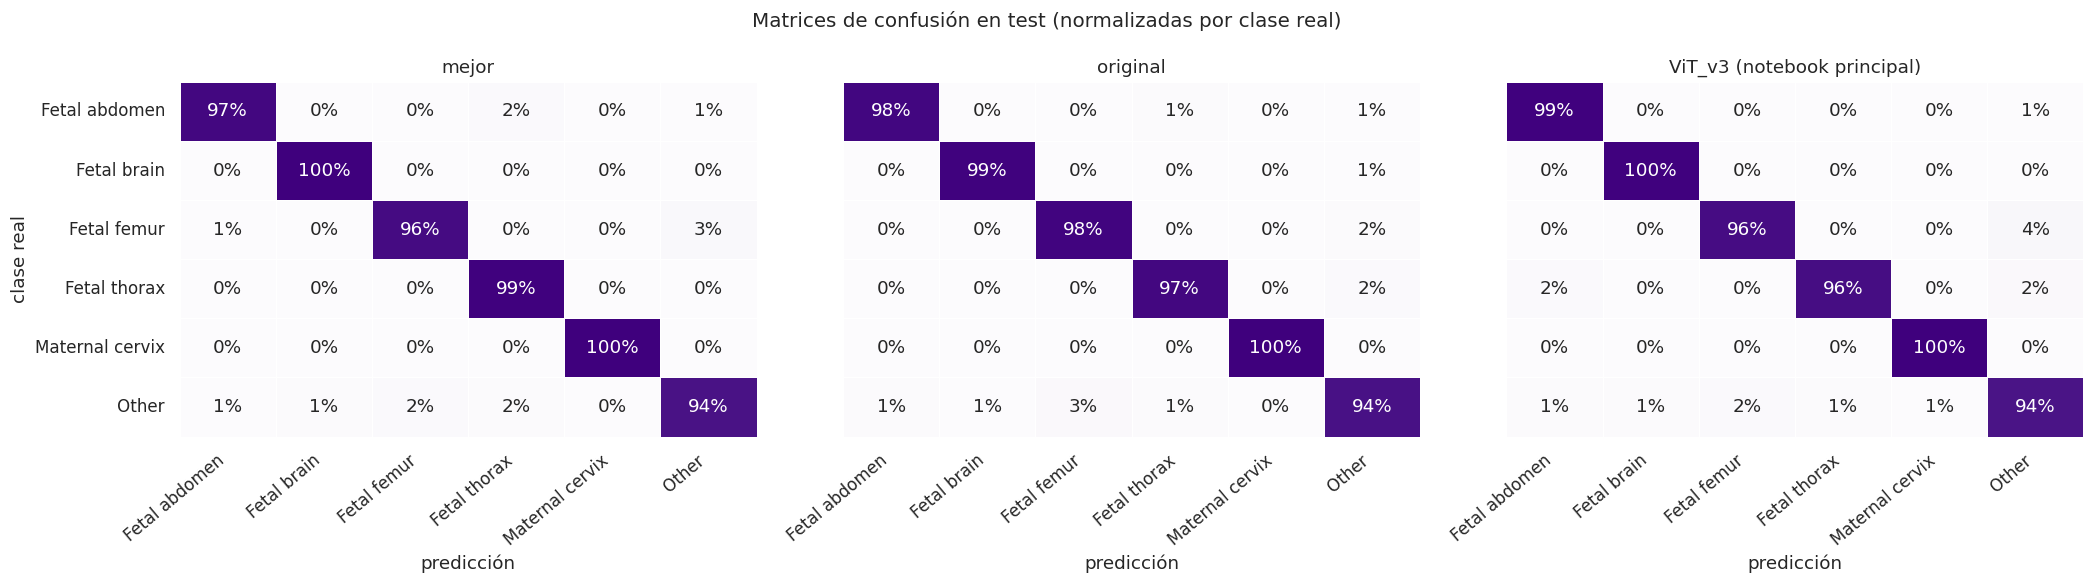

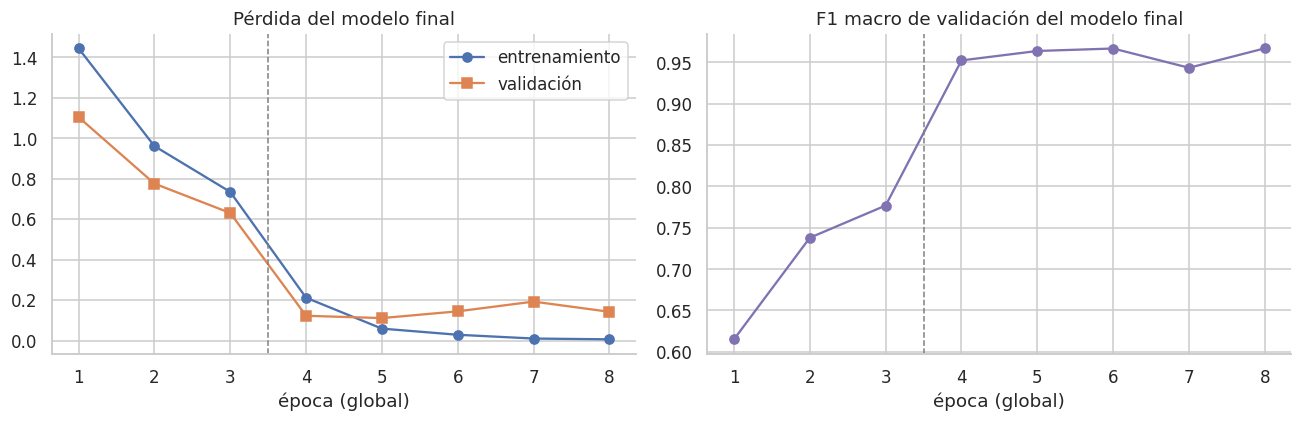

In [54]:
# 9c. resultados en test: mejor configuración vs original (misma condición) vs ViT_v3.pt del notebook principal
def evaluar_vit_v3():
    ruta = find_file('ViT_v3.pt')
    if ruta is None:
        return None
    try:
        m = ViTClassifier(num_classes).to(device); m.load_state_dict(torch.load(ruta, map_location=device))
    except Exception as e:           # p. ej. el archivo se guardó con otra versión de transformers (nombres de capas distintos)
        print('No se pudo cargar ViT_v3.pt con esta versión de transformers, se omite en la comparación:', str(e)[:120])
        return None
    probs, pred, rep = evaluar_test(m); del m; gc.collect()
    return dict(probs=probs, pred=pred, rep=rep)

if RUN_FINAL:
    v3 = evaluar_vit_v3()
    if v3 is not None:
        FINAL['ViT_v3 (notebook principal)'] = v3
    bi_te = boot_idx(pat_te, N_BOOT)
    filas = []
    for n, r in FINAL.items():
        a_, f_ = np.array([(r['pred'][i] == y_te[i]).mean() for i in bi_te]), np.array([macro_f1_fast(y_te[i], r['pred'][i]) for i in bi_te])
        filas.append({'Modelo': n, 'Accuracy': r['rep']['accuracy'], 'IC95 acc': f'[{np.percentile(a_, 2.5):.3f}, {np.percentile(a_, 97.5):.3f}]',
                      'F1 macro': r['rep']['macro avg']['f1-score'], 'IC95 F1': f'[{np.percentile(f_, 2.5):.3f}, {np.percentile(f_, 97.5):.3f}]'})
    comp = pd.DataFrame(filas).set_index('Modelo'); display(comp.round(4)); comp.to_csv(ABL_DIR / 'test_comparacion.csv')

    if 'original' in FINAL:                      # diferencia mejor - original con IC por pacientes y McNemar
        pm_, po_ = FINAL['mejor']['pred'], FINAL['original']['pred']
        dif = np.array([macro_f1_fast(y_te[i], pm_[i]) - macro_f1_fast(y_te[i], po_[i]) for i in bi_te]); lo, hi = np.percentile(dif, [2.5, 97.5])
        c_ = int(((po_ != y_te) & (pm_ == y_te)).sum()); b_ = int(((po_ == y_te) & (pm_ != y_te)).sum())
        p_ = stats.binomtest(min(b_, c_), b_ + c_, 0.5).pvalue if b_ + c_ else 1.0
        print(f'Test, mejor - original: ΔF1 macro = {macro_f1_fast(y_te, pm_) - macro_f1_fast(y_te, po_):+.4f}, IC 95 % por pacientes [{lo:+.4f}, {hi:+.4f}] | '
              f'McNemar exacto: {c_} aciertos solo de la mejor, {b_} solo de la original, p = {p_:.3f}')
        CONCL['test'] = dict(d=float(macro_f1_fast(y_te, pm_) - macro_f1_fast(y_te, po_)), lo=float(lo), hi=float(hi), p=float(p_), f1_mejor=float(macro_f1_fast(y_te, pm_)), f1_orig=float(macro_f1_fast(y_te, po_)))
        print('Si el IC incluye el 0, la diferencia no es concluyente con este test; en ese caso conviene decirlo así en el informe.')

    print('\nReporte por clase de la mejor configuración:')
    print(classification_report(y_te, FINAL['mejor']['pred'], target_names=classes, digits=3, zero_division=0))
    nm = list(FINAL)[:3]
    fig, axes = plt.subplots(1, len(nm), figsize=(6.4 * len(nm), 5.4), squeeze=False)
    for a, n in zip(axes[0], nm):
        cm = confusion_matrix(y_te, FINAL[n]['pred'], normalize='true')
        sns.heatmap(cm, annot=True, fmt='.0%', cmap='Purples', vmin=0, vmax=1, cbar=False, ax=a, xticklabels=classes,
                    yticklabels=classes if n == nm[0] else False, linewidths=.5, linecolor='white')
        a.set_title(n); a.set_xlabel('predicción'); a.tick_params(axis='x', rotation=40)
        for t in a.get_xticklabels(): t.set_ha('right')
    axes[0, 0].set_ylabel('clase real'); plt.suptitle('Matrices de confusión en test (normalizadas por clase real)', fontsize=13)
    plt.tight_layout(); plt.savefig(FIGS_DIR / 'test_confusion.png', dpi=150); plt.show()

    hh = pd.DataFrame(FINAL['mejor']['hist']); fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(hh['epoch'], hh['loss'], '-o', label='entrenamiento'); ax[0].plot(hh['epoch'], hh['val_loss'], '-s', label='validación'); ax[0].legend(); ax[0].set_title('Pérdida del modelo final')
    ax[1].plot(hh['epoch'], hh['val_f1'], '-o', color='#8172B2'); ax[1].set_title('F1 macro de validación del modelo final')
    n1 = int((hh.phase == 1).sum())
    for a in ax: a.axvline(n1 + 0.5, color='gray', ls='--', lw=1); a.set_xlabel('época (global)')
    plt.tight_layout(); plt.savefig(FIGS_DIR / 'final_curvas.png', dpi=150); plt.show()

### 9d. Épocas adicionales desde el checkpoint

Se parte de `ViT_B16_mejor_config.pt` y se entrena un poco más con tres variantes: **+3 épocas**, **+6 épocas** y **+6 épocas con lr/3 y coseno**. Solo se adopta una si **baja la pérdida de validación** respecto al checkpoint (nunca se decide con el test) y se guarda aparte; el checkpoint original no se sobrescribe.

Dos cosas a tener en cuenta: el checkpoint ya es el de menor pérdida de validación del entrenamiento (early stopping), así que es normal que seguir entrenando **no** mejore, y eso es un resultado válido (el modelo ya había convergido). Además el archivo no guarda el estado del optimizador, así que cada continuación reinicia AdamW; no es una continuación exacta.

Checkpoint de partida: val_loss 0.1108 | val_F1 0.9636


,val_loss,val_F1,Δ val_loss,mejora,minutos
experimento,,,,,
+3 épocas,0.1111,0.9628,0.0003,False,3.3025
+6 épocas,0.1097,0.9676,-0.0011,True,6.5226
"+6 épocas, lr/3 y coseno",0.1229,0.9655,0.0121,False,6.5270


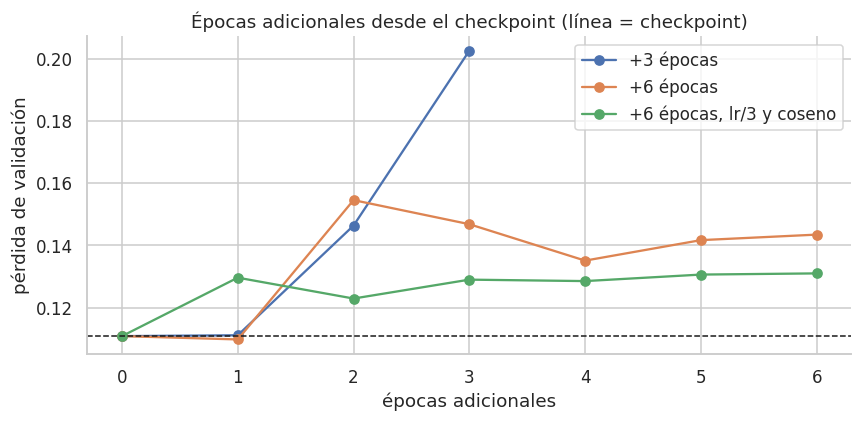

Se adopta '+6 épocas' (bajó la pérdida de validación de 0.1108 a 0.1097). Guardado en ViT_B16_mejor_config_extra_epocas.pt; el checkpoint original no se tocó.
  Test (solo informativo, no se usó para decidir): accuracy 0.9769 | F1 macro 0.9734 | checkpoint original 0.9712


In [55]:
# 9d. continuar el entrenamiento desde el mejor checkpoint (misma partición de entrenamiento y validación del entrenamiento final)
EXTRA = {'+3 épocas': dict(n=3), '+6 épocas': dict(n=6), '+6 épocas, lr/3 y coseno': dict(n=6, lr_div=3, sched='cosine')}
EXTRA_PATH = ABL_DIR / 'ViT_B16_mejor_config_extra_epocas.pt'

def continuar(n, lr_div=1, sched=None):
    model, ck = cargar_vit(CKPT_PATH)
    cfg = {**ck['cfg'], 'ep_fine': n, 'lr_fine': ck['cfg']['lr_fine'] / lr_div, **({'sched': sched} if sched else {})}
    set_trainable(model, cfg['unfreeze'])
    hist = {k: [] for k in ('epoch', 'phase', 'loss', 'val_loss', 'val_acc', 'val_f1', 'lr')}
    run_phase(model, grupos_fine(model, cfg['lr_fine'], cfg['wd'], cfg['llrd']), n, 10**6, Xpool[fit_f], y_pool[fit_f], Xpool[val_f], y_pool[val_f],
              pesos_clase(y_pool[fit_f], cfg.get('class_weights', True)), cfg, 2, hist)
    return model, ck, cfg, hist

if RUN_EXTRA_EPOCAS and CKPT_PATH.exists():
    m0_model, ck0 = cargar_vit(CKPT_PATH); m0 = metricas(predict_probs(m0_model, Xpool[val_f]), y_pool[val_f]); del m0_model
    print(f"Checkpoint de partida: val_loss {m0['loss']:.4f} | val_F1 {m0['f1']:.4f}")
    filas_e, modelos_e, curvas_e = [], {}, {}
    for nombre, kw in EXTRA.items():
        t0 = time.time(); model_e, ck_e, cfg_e, hist_e = continuar(**kw)
        me = metricas(predict_probs(model_e, Xpool[val_f]), y_pool[val_f]); curvas_e[nombre] = hist_e['val_loss']
        filas_e.append({'experimento': nombre, 'val_loss': me['loss'], 'val_F1': me['f1'], 'Δ val_loss': me['loss'] - m0['loss'],
                        'mejora': me['loss'] < m0['loss'] - 1e-4, 'minutos': (time.time() - t0) / 60})
        modelos_e[nombre] = (({k: v.detach().cpu().clone() for k, v in model_e.state_dict().items()}), cfg_e)
        del model_e; gc.collect()
        if device == 'cuda': torch.cuda.empty_cache()
    te = pd.DataFrame(filas_e).set_index('experimento'); display(te.round(4)); te.to_csv(ABL_DIR / 'epocas_adicionales.csv')
    fig, ax = plt.subplots(figsize=(8, 4))
    for n, v in curvas_e.items():
        ax.plot(np.arange(0, len(v) + 1), [m0['loss']] + v, '-o', label=n)
    ax.axhline(m0['loss'], color='k', ls='--', lw=1); ax.set_xlabel('épocas adicionales'); ax.set_ylabel('pérdida de validación'); ax.legend(); ax.set_title('Épocas adicionales desde el checkpoint (línea = checkpoint)')
    plt.tight_layout(); plt.savefig(FIGS_DIR / 'epocas_adicionales.png', dpi=150); plt.show()
    mejores = te[te['mejora']]
    if len(mejores):
        ganador = mejores['val_loss'].idxmin(); sd, cfg_g = modelos_e[ganador]
        mg = ViTClassifier(num_classes, cfg_g['head'], cfg_g['head_dropout']).to(device); mg.load_state_dict(sd)
        pr_, pd_, rep_ = evaluar_test(mg); del mg
        ck_nuevo = {**ck0, 'state_dict': sd, 'cfg': cfg_g, 'extra_epocas': ganador}
        ck_nuevo['test'] = {'accuracy': float(rep_['accuracy']), 'f1_macro': float(rep_['macro avg']['f1-score']), 'f1_por_clase': {c: float(rep_[c]['f1-score']) for c in classes}}
        torch.save(ck_nuevo, EXTRA_PATH)
        print(f"Se adopta '{ganador}' (bajó la pérdida de validación de {m0['loss']:.4f} a {te.loc[ganador, 'val_loss']:.4f}). Guardado en {EXTRA_PATH.name}; el checkpoint original no se tocó.")
        print(f"  Test (solo informativo, no se usó para decidir): accuracy {rep_['accuracy']:.4f} | F1 macro {rep_['macro avg']['f1-score']:.4f} | checkpoint original {FINAL['mejor']['rep']['macro avg']['f1-score']:.4f}" if 'mejor' in FINAL else '')
        CONCL['extra'] = dict(adoptado=ganador, tabla=te)
    else:
        print('Ninguna variante bajó la pérdida de validación: el checkpoint ya había convergido y se conserva tal cual.')
        CONCL['extra'] = dict(adoptado=None, tabla=te)
else:
    print('Se omite 9d (RUN_EXTRA_EPOCAS=False o no existe el checkpoint).')

## 10. Explicabilidad del mejor ViT

En el notebook principal solo se usaba **Attention Rollout** para el ViT. Aquí se agregan cuatro métodos más sobre el modelo guardado en la sección 9:

| Método | Qué mide | Naturaleza |
|---|---|---|
| **Attention Rollout** | Cómo se propaga la atención del token CLS hacia los parches a través de las 12 capas (promedio de cabezas + conexión residual) | Solo atención, no depende de la clase |
| **Atención de la última capa** | Atención directa CLS → parches en el último bloque | Solo atención, no depende de la clase |
| **Rollout ponderado por gradiente** | Como el rollout, pero cada capa pondera la atención por su gradiente (positivo) respecto a la clase; variante simplificada de Chefer et al. | Depende de la clase |
| **Integrated Gradients** | Atribución a nivel de píxel desde una imagen negra, 30 pasos (igual que en las CNNs del notebook principal; el mapa se suaviza con un gaussiano de σ=3 px para poder verlo) | Depende de la clase |
| **Oclusión** | Caída de la probabilidad de la clase al tapar ventanas de 32×32 (paso 16) con la imagen desenfocada | Depende de la clase, no usa gradientes |

**Grad-CAM no se incluye**: necesita mapas convolucionales y el ViT no los tiene. Su adaptación a tokens (activaciones de los parches del último bloque) dio un resultado indistinguible del azar en una corrida previa de este notebook (Inserción − Borrado de 0,028 contra 0,002 de un mapa aleatorio), así que se descartó. Para el ViT se usan métodos basados en atención o en perturbación.

Los mapas basados solo en atención **no** dependen de la clase que se explica y no hay garantía de que reflejen lo que usa la decisión; los métodos con gradiente u oclusión sí se calculan para la clase predicha. Por eso se evalúan los cinco con las mismas pruebas cuantitativas (10c): borrado e inserción, concentración en bordes y esquinas y acuerdo entre métodos; se comparan entre sí con pruebas pareadas (10e) y se someten a comprobaciones de sensatez (10f).

In [56]:
# 10a. métodos de explicabilidad (todos devuelven un mapa 224x224 en [0, 1])
GRID = IMG_SIZE // 16
BLUR_SIGMA = 15

def _prep(rgb):
    return normalize(torch.from_numpy(rgb[None]).to(device).permute(0, 3, 1, 2).float() / 255.0)

def _norm(m):
    m = np.maximum(np.asarray(m, dtype=np.float32), 0)
    return m / (m.max() + 1e-8)

def _up(m_grid):
    return _norm(cv2.resize(_norm(m_grid), (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_CUBIC))

@torch.no_grad()
def xai_rollout(model, rgb, cls=None):
    # igual que en el notebook principal: promedio de cabezas + identidad, normalizado por filas, producto de capas
    logits, atts = model(_prep(rgb), output_attentions=True)
    T = atts[0].shape[-1]; R = torch.eye(T, device=device)
    for a in atts:
        a = a[0].float().mean(0) + torch.eye(T, device=device); a = a / a.sum(-1, keepdim=True); R = a @ R
    return _up(R[0, 1:].reshape(GRID, GRID).cpu().numpy())

@torch.no_grad()
def xai_ultima_capa(model, rgb, cls=None):
    logits, atts = model(_prep(rgb), output_attentions=True)
    return _up(atts[-1][0].float().mean(0)[0, 1:].reshape(GRID, GRID).cpu().numpy())

def xai_grad_rollout(model, rgb, cls=None):
    x = _prep(rgb).requires_grad_(True)
    logits, atts = model(x, output_attentions=True); logits = logits.float()
    c = int(logits.argmax(1)) if cls is None else cls
    grads = torch.autograd.grad(logits[0, c], list(atts))
    T = atts[0].shape[-1]; R = torch.eye(T, device=device)
    for a, g in zip(atts, grads):
        Abar = (g[0].float() * a[0].float()).clamp(min=0).mean(0)       # (gradiente x atención)+ promediado en cabezas
        R = R + Abar @ R
    return _up(R[0, 1:].reshape(GRID, GRID).detach().cpu().numpy())

def xai_ig(model, rgb, cls=None, steps=30, bs=8):
    img = torch.from_numpy(rgb[None]).to(device).permute(0, 3, 1, 2).float() / 255.0
    if cls is None:
        with torch.no_grad():
            cls = int(model(normalize(img)).argmax(1))
    alphas = torch.linspace(0, 1, steps + 1, device=device).view(-1, 1, 1, 1); grads = []
    for i in range(0, steps + 1, bs):
        xb = (alphas[i:i + bs] * img).requires_grad_(True)
        g, = torch.autograd.grad(model(normalize(xb)).float()[:, cls].sum(), xb); grads.append(g.detach())
    hm = (img * torch.cat(grads).mean(0, keepdim=True)).abs().mean(1)[0].cpu().numpy()
    return _norm(cv2.GaussianBlur(hm, (0, 0), 3))

@torch.no_grad()
def xai_oclusion(model, rgb, cls=None, win=32, stride=16, bs=64):
    x0 = _prep(rgb); p0 = torch.softmax(model(x0).float(), -1)[0]
    c = int(p0.argmax()) if cls is None else cls
    xb = _prep(cv2.GaussianBlur(rgb, (0, 0), BLUR_SIGMA))
    pos = [(y, x) for y in range(0, IMG_SIZE - win + 1, stride) for x in range(0, IMG_SIZE - win + 1, stride)]
    acc, cnt = np.zeros((IMG_SIZE, IMG_SIZE), np.float32), np.zeros((IMG_SIZE, IMG_SIZE), np.float32)
    for i in range(0, len(pos), bs):
        ch = pos[i:i + bs]; xs = x0.repeat(len(ch), 1, 1, 1)
        for j, (y, x) in enumerate(ch):
            xs[j, :, y:y + win, x:x + win] = xb[0, :, y:y + win, x:x + win]
        p = torch.softmax(model(xs).float(), -1)[:, c].cpu().numpy()
        for j, (y, x) in enumerate(ch):
            acc[y:y + win, x:x + win] += float(p0[c]) - p[j]; cnt[y:y + win, x:x + win] += 1
    return _norm(acc / np.maximum(cnt, 1))

METODOS = {'Attention Rollout': xai_rollout, 'Atención última capa': xai_ultima_capa, 'Rollout x gradiente': xai_grad_rollout, 'Integrated Gradients': xai_ig, 'Oclusión': xai_oclusion}
SOLO_ATENCION = {'Attention Rollout', 'Atención última capa'}

def xai_todos(model, rgb, cls):
    return {n: f(model, rgb, cls) for n, f in METODOS.items()}

# modelo con atención "eager" (la implementación rápida no devuelve las atenciones); se carga del archivo guardado
assert CKPT_PATH.exists(), 'No hay modelo guardado: ejecutar la sección 9 (RUN_FINAL=True)'
model_x, ck_x = cargar_vit(CKPT_PATH, attn='eager')
for p in model_x.parameters():
    p.requires_grad_(False)
probs_te = predict_probs(model_x, Xte); pred_te = probs_te.argmax(1)
print('Modelo cargado de', CKPT_PATH.name, '| accuracy en test:', round(float((pred_te == y_te).mean()), 4))

# comprobación: sin gradientes y con ellos, el rollout y la clase predicha deben coincidir con el forward normal
_r = Xte[0]; _m = xai_todos(model_x, _r, int(pred_te[0]))
print('mapas de prueba:', {k: (v.shape, round(float(v.max()), 2)) for k, v in _m.items()})

Modelo cargado de ViT_B16_mejor_config.pt | accuracy en test: 0.9742
mapas de prueba: {'Attention Rollout': ((224, 224), 1.0), 'Atención última capa': ((224, 224), 1.0), 'Rollout x gradiente': ((224, 224), 1.0), 'Integrated Gradients': ((224, 224), 1.0), 'Oclusión': ((224, 224), 1.0)}


ViT-B/16 mejor configuración: aciertos con confianza alta (un caso por clase):   0%|          | 0/6 [00:00<?, …

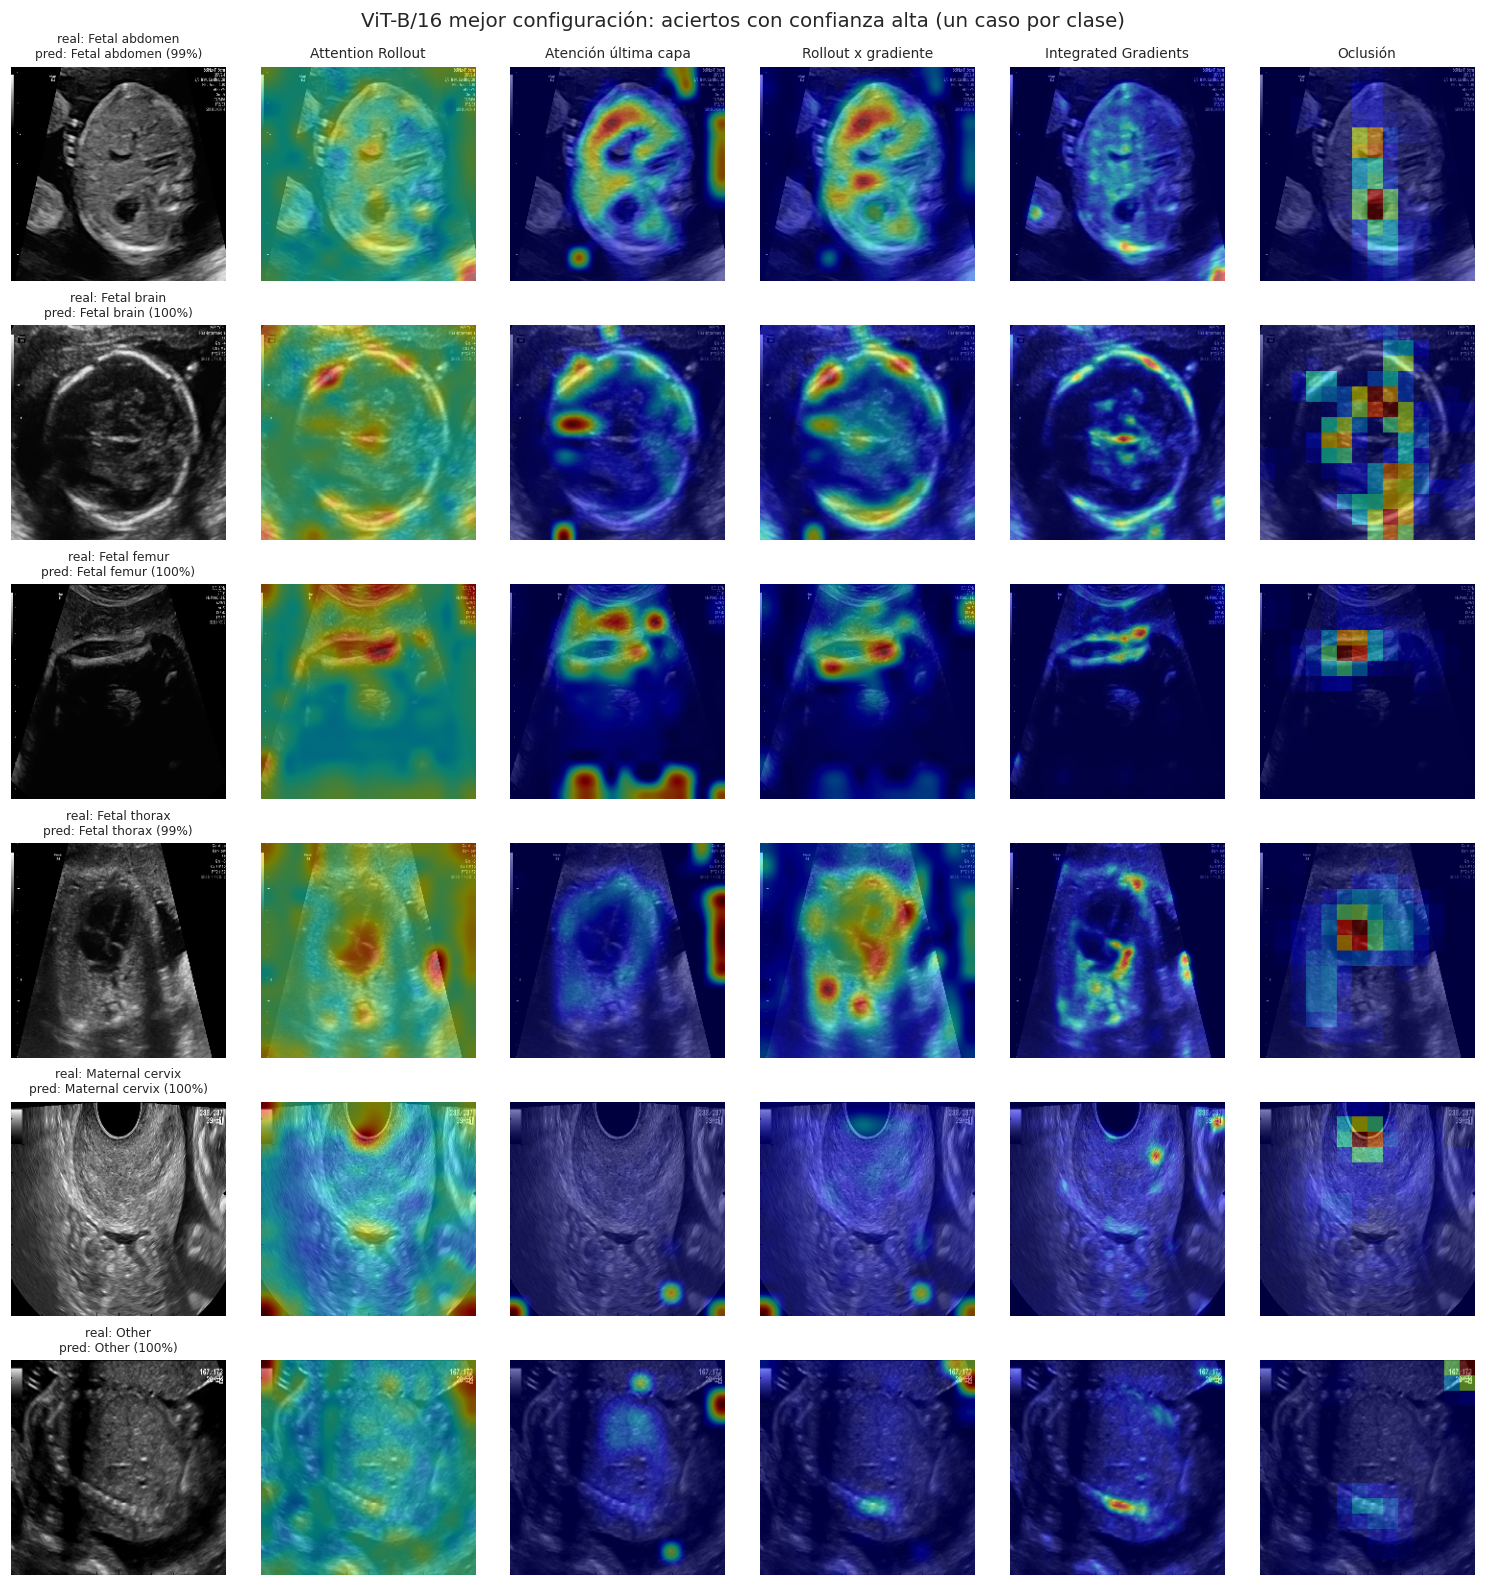

ViT-B/16 mejor configuración: errores con mayor confianza:   0%|          | 0/3 [00:00<?, ?it/s]

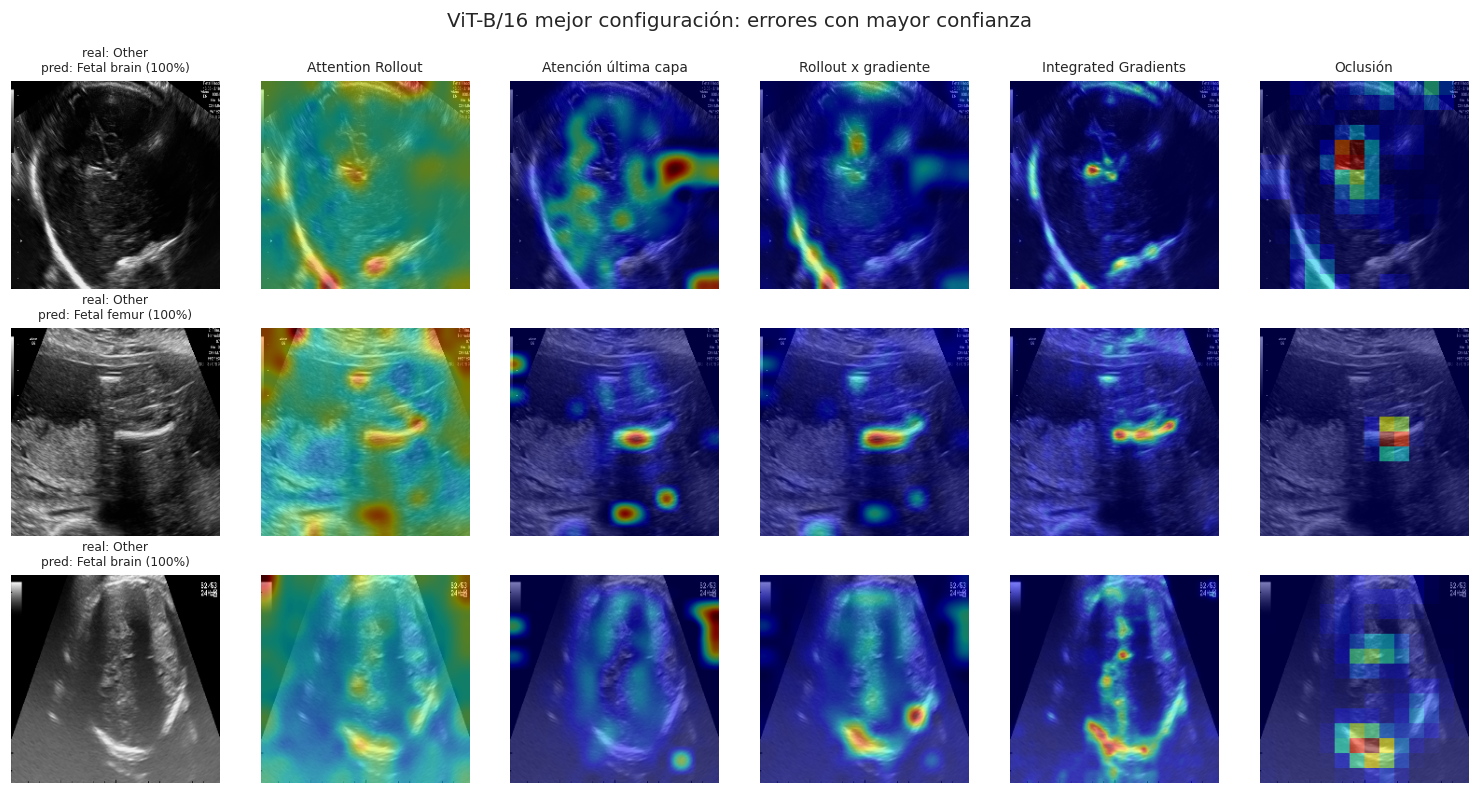

In [57]:
# 10b. comparación visual: casos acertados con confianza alta (uno por clase) y los errores más seguros
rng_q = np.random.default_rng(5)
conf = probs_te.max(1); ok = pred_te == y_te
IDX_OK = []
for c in range(num_classes):
    cand = np.where(ok & (y_te == c) & (conf > 0.9))[0]
    if len(cand) == 0: cand = np.where(ok & (y_te == c))[0]
    if len(cand): IDX_OK.append(int(rng_q.choice(cand)))
err = np.where(~ok)[0]; IDX_ERR = [int(i) for i in err[np.argsort(-conf[err])][:3]]

def figura_xai(indices, titulo, fname):
    nm = list(METODOS); fig, axes = plt.subplots(len(indices), 1 + len(nm), figsize=(2.3 * (1 + len(nm)), 2.45 * len(indices)), squeeze=False)
    for r, i in enumerate(tqdm(indices, desc=titulo, leave=False)):
        rgb = Xte[i]; c = int(pred_te[i]); mapas = xai_todos(model_x, rgb, c)
        axes[r, 0].imshow(rgb); axes[r, 0].set_title(f'real: {classes[y_te[i]]}\npred: {classes[c]} ({conf[i]*100:.0f}%)', fontsize=8)
        for k, n in enumerate(nm):
            axes[r, k + 1].imshow(rgb); axes[r, k + 1].imshow(mapas[n], cmap='jet', alpha=0.5, vmin=0, vmax=1)
            if r == 0: axes[r, k + 1].set_title(n, fontsize=9)
        for a in axes[r]: a.axis('off')
    fig.suptitle(titulo, fontsize=13); plt.tight_layout(); plt.savefig(FIGS_DIR / fname, dpi=130); plt.show()

figura_xai(IDX_OK, 'ViT-B/16 mejor configuración: aciertos con confianza alta (un caso por clase)', 'xai_vit_aciertos.png')
if IDX_ERR:
    figura_xai(IDX_ERR, 'ViT-B/16 mejor configuración: errores con mayor confianza', 'xai_vit_errores.png')

evaluando mapas:   0%|          | 0/100 [00:00<?, ?it/s]

,Borrado AUC (menor mejor),Inserción AUC (mayor mejor),Inserción - Borrado (mayor mejor),Enriq. borde,Enriq. esquinas,p Wilcoxon vs aleatorio
metodo,,,,,,
Attention Rollout,0.417,0.795,0.378,1.084,1.126,0.000
Atención última capa,0.508,0.776,0.268,1.004,1.092,0.000
Rollout x gradiente,0.357,0.889,0.531,0.857,0.947,0.000
Integrated Gradients,0.436,0.888,0.451,0.620,0.539,0.000
Oclusión,0.392,0.922,0.529,0.778,0.928,0.000
Aleatorio (píxeles),0.688,0.688,-0.000,1.000,1.001,0.754
Aleatorio (parches),0.673,0.683,0.011,1.002,0.991,NaN


(N = 100 imágenes de test). Solo las 40 imágenes del notebook principal, para comparar con sus cifras:


,borrado_auc,insercion_auc,ins_menos_borr
metodo,,,
Attention Rollout,0.384,0.796,0.411
Atención última capa,0.505,0.749,0.245
Rollout x gradiente,0.307,0.884,0.576
Integrated Gradients,0.408,0.884,0.476
Oclusión,0.355,0.911,0.556
Aleatorio (píxeles),0.661,0.664,0.003
Aleatorio (parches),0.641,0.664,0.023


Enriquecimiento 1,0 = mapa uniforme; mayor que 1 = más masa de la esperada en el borde/esquinas, donde suelen estar los rótulos del equipo.


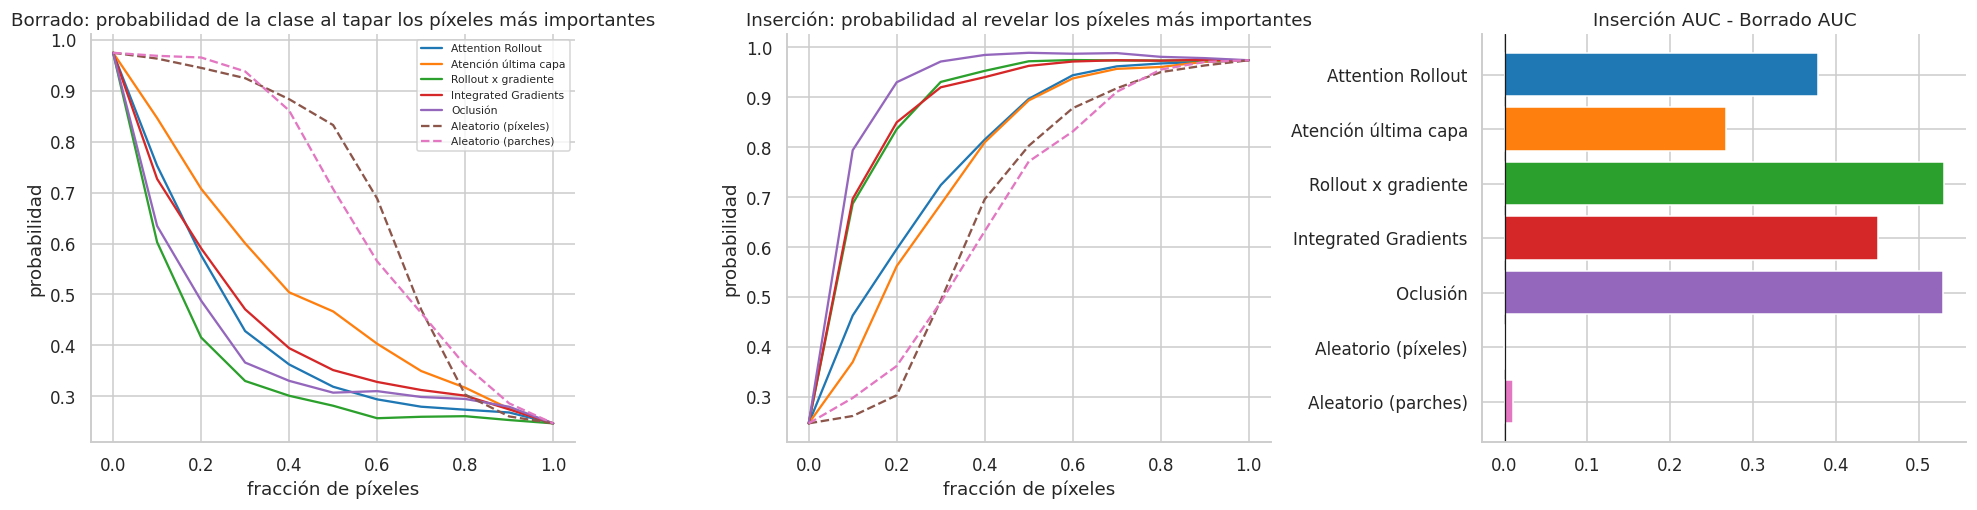

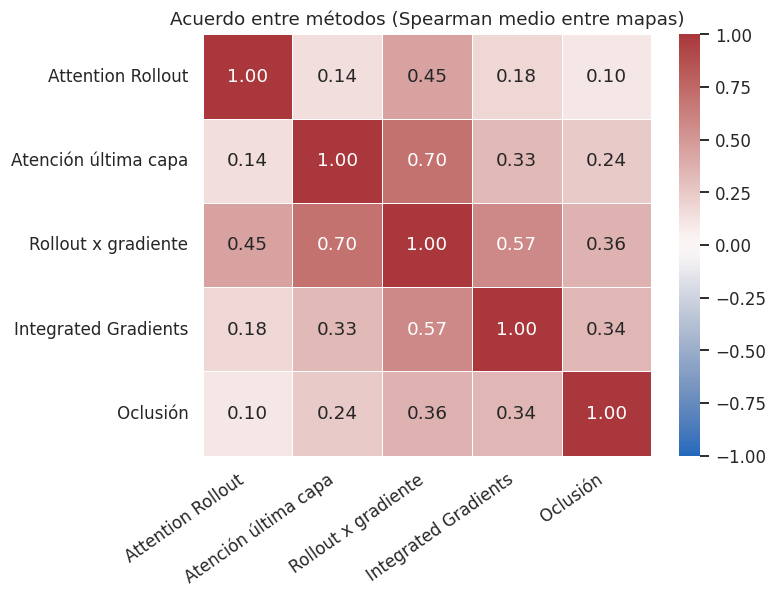

In [58]:
# 10c. evaluación cuantitativa de los mapas: borrado, inserción, bordes/esquinas y acuerdo entre métodos
# Borrado: se tapan primero los píxeles más importantes del mapa; si el mapa es bueno, la probabilidad cae rápido (AUC bajo).
# Inserción: se parte de la imagen desenfocada y se revelan primero esos píxeles; si es bueno, la probabilidad sube rápido (AUC alto).
# Se usan los dos mapas "Aleatorio" como referencia de un mapa sin información (píxeles sueltos y bloques de 14x14, como los de un ViT).
# Las primeras 40 imágenes son las mismas del notebook principal (misma semilla de selección), así se pueden comparar con sus tablas;
# hasta N_XAI_EVAL se agregan imágenes adicionales para estrechar los intervalos.
FRACS = np.linspace(0, 1, 11)
IDX_V4 = np.random.default_rng(11).choice(len(y_te), size=min(40, len(y_te)), replace=False)
_resto = np.setdiff1d(np.arange(len(y_te)), IDX_V4)
_extra = np.random.default_rng(12).choice(_resto, size=max(0, min(N_XAI_EVAL, len(y_te)) - len(IDX_V4)), replace=False)
IDX_EVAL = np.concatenate([IDX_V4, _extra])
rng_r = np.random.default_rng(3)

def auc(y, x=FRACS):
    return float(np.sum((y[1:] + y[:-1]) / 2 * np.diff(x)))

@torch.no_grad()
def curva_pert(rgb, blur, hm, c, modo):
    orden = np.argsort(-hm.ravel(), kind='stable'); n = orden.size; imgs = []
    for f in FRACS:
        mask = np.zeros(n, bool); mask[orden[:int(round(f * n))]] = True; mask = mask.reshape(IMG_SIZE, IMG_SIZE, 1)
        imgs.append(np.where(mask, blur, rgb) if modo == 'borrado' else np.where(mask, rgb, blur))
    x = normalize(torch.from_numpy(np.stack(imgs)).to(device).permute(0, 3, 1, 2).float() / 255.0)
    return torch.softmax(model_x(x).float(), -1)[:, c].cpu().numpy()

yy, xx = np.mgrid[:IMG_SIZE, :IMG_SIZE]
B_, E_ = int(round(0.10 * IMG_SIZE)), int(round(0.20 * IMG_SIZE))
ZONAS = {'Borde (10 %)': (yy < B_) | (yy >= IMG_SIZE - B_) | (xx < B_) | (xx >= IMG_SIZE - B_),
         'Esquinas (4 x 20 %)': ((yy < E_) | (yy >= IMG_SIZE - E_)) & ((xx < E_) | (xx >= IMG_SIZE - E_))}
def enriquecimiento(hm):
    # (fracción de la masa del mapa en la zona) / (fracción del área de la zona): 1 = mapa uniforme, > 1 = más peso del esperado
    hm = np.maximum(hm.astype(np.float64), 0); tot = hm.sum() + 1e-12
    return {z: float(hm[m].sum() / tot / m.mean()) for z, m in ZONAS.items()}

filas, curvas, mapas_bajos = [], {}, []
for i in tqdm(IDX_EVAL, desc='evaluando mapas'):
    rgb = Xte[i]; blur = cv2.GaussianBlur(rgb, (0, 0), BLUR_SIGMA); c = int(pred_te[i])
    mapas = xai_todos(model_x, rgb, c)
    mapas_bajos.append({n: cv2.resize(m, (56, 56), interpolation=cv2.INTER_AREA).ravel() for n, m in mapas.items()})
    mapas['Aleatorio (píxeles)'] = rng_r.random((IMG_SIZE, IMG_SIZE)).astype(np.float32)
    mapas['Aleatorio (parches)'] = cv2.resize(rng_r.random((GRID, GRID)).astype(np.float32), (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_NEAREST)
    for n, hm in mapas.items():
        cb, ci = curva_pert(rgb, blur, hm, c, 'borrado'), curva_pert(rgb, blur, hm, c, 'insercion')
        curvas.setdefault(n, {'borrado': [], 'insercion': []}); curvas[n]['borrado'].append(cb); curvas[n]['insercion'].append(ci)
        filas.append(dict(img=int(i), metodo=n, borrado_auc=auc(cb), insercion_auc=auc(ci), **enriquecimiento(hm)))
xai_df = pd.DataFrame(filas); xai_df['ins_menos_borr'] = xai_df['insercion_auc'] - xai_df['borrado_auc']; xai_df['en_v4'] = xai_df['img'].isin(IDX_V4)
orden_m = list(METODOS) + ['Aleatorio (píxeles)', 'Aleatorio (parches)']
ref = xai_df[xai_df.metodo == 'Aleatorio (parches)'].set_index('img')['ins_menos_borr']
tabla_xai = xai_df.groupby('metodo')[['borrado_auc', 'insercion_auc', 'ins_menos_borr', 'Borde (10 %)', 'Esquinas (4 x 20 %)']].mean().loc[orden_m]
tabla_xai['p vs aleatorio (parches)'] = [np.nan if n == 'Aleatorio (parches)' else
                                          stats.wilcoxon(xai_df[xai_df.metodo == n].set_index('img')['ins_menos_borr'].loc[ref.index], ref).pvalue for n in orden_m]
tabla_xai.columns = ['Borrado AUC (menor mejor)', 'Inserción AUC (mayor mejor)', 'Inserción - Borrado (mayor mejor)', 'Enriq. borde', 'Enriq. esquinas', 'p Wilcoxon vs aleatorio']
display(tabla_xai.round(3)); tabla_xai.to_csv(ABL_DIR / 'xai_cuantitativo.csv')
print(f'(N = {len(IDX_EVAL)} imágenes de test). Solo las 40 imágenes del notebook principal, para comparar con sus cifras:')
display(xai_df[xai_df.en_v4].groupby('metodo')[['borrado_auc', 'insercion_auc', 'ins_menos_borr']].mean().loc[orden_m].round(3))
CONCL['xai_tabla'] = tabla_xai
print('Enriquecimiento 1,0 = mapa uniforme; mayor que 1 = más masa de la esperada en el borde/esquinas, donde suelen estar los rótulos del equipo.')

fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
pal = dict(zip(orden_m, sns.color_palette('tab10', len(orden_m))))
for n in orden_m:
    st = '--' if n.startswith('Aleatorio') else '-'
    ax[0].plot(FRACS, np.mean(curvas[n]['borrado'], 0), st, color=pal[n], label=n); ax[1].plot(FRACS, np.mean(curvas[n]['insercion'], 0), st, color=pal[n], label=n)
ax[0].set_title('Borrado: probabilidad de la clase al tapar los píxeles más importantes'); ax[1].set_title('Inserción: probabilidad al revelar los píxeles más importantes')
for a in ax[:2]: a.set_xlabel('fracción de píxeles'); a.set_ylabel('probabilidad')
ax[0].legend(fontsize=7)
t_ = tabla_xai['Inserción - Borrado (mayor mejor)'].loc[orden_m]; ax[2].barh(range(len(t_)), t_.values, color=[pal[n] for n in orden_m]); ax[2].set_yticks(range(len(t_))); ax[2].set_yticklabels(orden_m)
ax[2].invert_yaxis(); ax[2].set_title('Inserción AUC - Borrado AUC'); ax[2].axvline(0, color='k', lw=.8)
plt.tight_layout(); plt.savefig(FIGS_DIR / 'xai_borrado_insercion.png', dpi=150); plt.show()

# acuerdo entre métodos: correlación de Spearman entre mapas (a 56x56), promediada sobre las imágenes
nm = list(METODOS); S = np.zeros((len(nm), len(nm)))
for d in mapas_bajos:
    S += stats.spearmanr(np.stack([d[n] for n in nm], 1)).statistic
S /= len(mapas_bajos)
plt.figure(figsize=(7.2, 5.6)); sns.heatmap(pd.DataFrame(S, index=nm, columns=nm), annot=True, fmt='.2f', cmap='vlag', vmin=-1, vmax=1, linewidths=.5)
plt.title('Acuerdo entre métodos (Spearman medio entre mapas)'); plt.xticks(rotation=35, ha='right'); plt.tight_layout()
plt.savefig(FIGS_DIR / 'xai_acuerdo_metodos.png', dpi=150); plt.show()

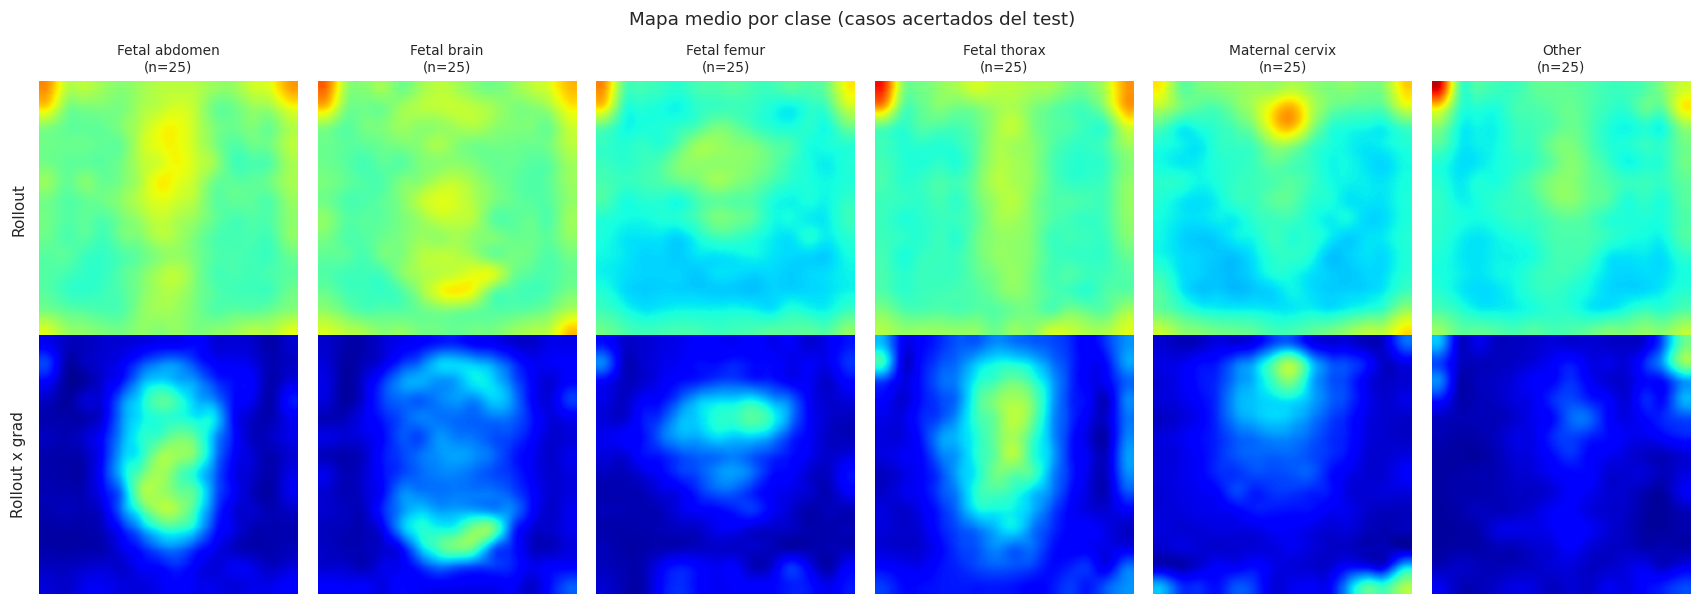

In [59]:
# 10d. ¿dónde mira el ViT en cada plano? mapa medio de Attention Rollout y de Rollout x gradiente por clase (solo aciertos)
fig, axes = plt.subplots(2, num_classes, figsize=(2.6 * num_classes, 5.6), squeeze=False)
for c in range(num_classes):
    idx = np.where((y_te == c) & ok)[0]; idx = np.random.default_rng(7).choice(idx, size=min(25, len(idx)), replace=False)
    for r, f in enumerate((xai_rollout, xai_grad_rollout)):
        axes[r, c].axis('off')
        if len(idx):
            axes[r, c].imshow(np.mean([f(model_x, Xte[i], c) for i in idx], 0), cmap='jet', vmin=0, vmax=1)
        if r == 0: axes[r, c].set_title(f'{classes[c]}\n(n={len(idx)})', fontsize=9)
axes[0, 0].text(-0.05, 0.5, 'Rollout', transform=axes[0, 0].transAxes, rotation=90, va='center', ha='right', fontsize=10)
axes[1, 0].text(-0.05, 0.5, 'Rollout x grad', transform=axes[1, 0].transAxes, rotation=90, va='center', ha='right', fontsize=10)
plt.suptitle('Mapa medio por clase (casos acertados del test)', fontsize=12); plt.tight_layout(); plt.savefig(FIGS_DIR / 'xai_mapa_medio_clase.png', dpi=150); plt.show()

### 10e. Comparación estadística entre métodos

Con los mismos mapas de 10c se compara el puntaje **Inserción − Borrado** (mayor = más fiel al modelo) entre todos los pares de métodos, **por imagen** (pruebas pareadas: la misma imagen se evalúa con todos los métodos). Cada diferencia lleva un intervalo de confianza que remuestrea **pacientes** (no imágenes, porque las imágenes de un paciente no son independientes), una prueba de Wilcoxon y la corrección de **Holm** por comparaciones múltiples (una familia para los pares entre métodos y otra para cada método contra el mapa aleatorio de parches).

N = 100 imágenes, 84 pacientes. Puntaje = Inserción AUC - Borrado AUC.

Cada método contra el mapa aleatorio de parches:


,metodo,dif_vs_azar,lo,hi,p,p_Holm,mejor_que_azar
0,Attention Rollout,0.3678,0.3044,0.4354,0.0,0.0,True
1,Atención última capa,0.2570,0.1801,0.3357,0.0,0.0,True
2,Rollout x gradiente,0.5205,0.4516,0.5919,0.0,0.0,True
3,Integrated Gradients,0.4406,0.3716,0.5128,0.0,0.0,True
4,Oclusión,0.5188,0.4559,0.5882,0.0,0.0,True



Pares de métodos (dif = A - B):


,A,B,dif,lo,hi,p,p_Holm,significativa
0,Attention Rollout,Atención última capa,0.1108,0.0566,0.1710,0.0003,0.0009,True
1,Attention Rollout,Rollout x gradiente,-0.1527,-0.1890,-0.1196,0.0000,0.0000,True
2,Attention Rollout,Integrated Gradients,-0.0728,-0.1151,-0.0353,0.0002,0.0007,True
3,Attention Rollout,Oclusión,-0.1510,-0.2054,-0.0966,0.0000,0.0000,True
4,Atención última capa,Rollout x gradiente,-0.2635,-0.3301,-0.2042,0.0000,0.0000,True
5,Atención última capa,Integrated Gradients,-0.1836,-0.2265,-0.1457,0.0000,0.0000,True
6,Atención última capa,Oclusión,-0.2618,-0.3302,-0.1908,0.0000,0.0000,True
7,Rollout x gradiente,Integrated Gradients,0.0799,0.0401,0.1233,0.0001,0.0004,True
8,Rollout x gradiente,Oclusión,0.0017,-0.0456,0.0551,0.8960,0.8960,False
9,Integrated Gradients,Oclusión,-0.0782,-0.1328,-0.0229,0.0100,0.0200,True


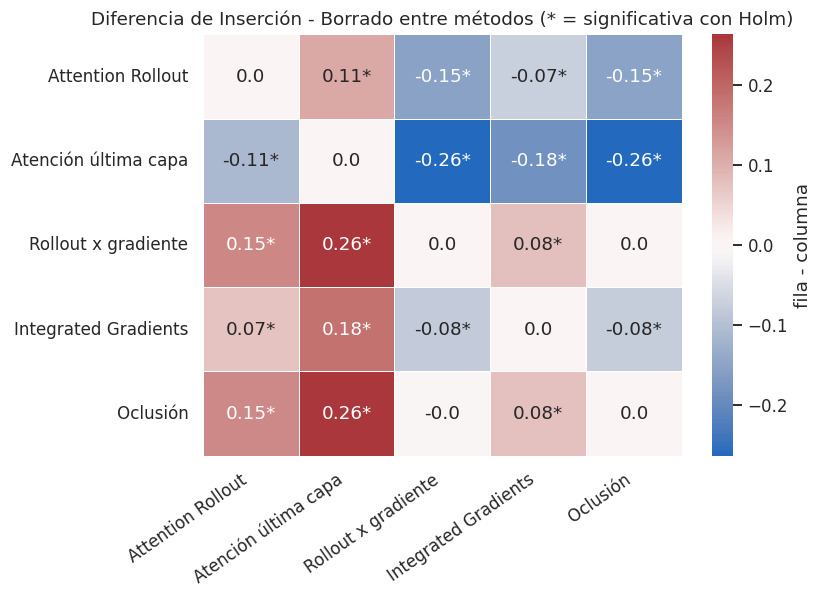


Ranking por puntaje medio: Rollout x gradiente (0.53) > Oclusión (0.53) > Integrated Gradients (0.45) > Attention Rollout (0.38) > Atención última capa (0.27)
El primero (Rollout x gradiente) NO se distingue del segundo (Oclusión) tras la corrección de Holm.


In [60]:
# 10e. diferencias pareadas entre métodos, intervalos por pacientes y corrección de Holm
import itertools
def holm(p):
    p = np.asarray(p, float); o = np.argsort(p); m = len(p); adj = np.empty(m); run = 0.0
    for k, i in enumerate(o):
        run = max(run, (m - k) * p[i]); adj[i] = min(1.0, run)
    return adj

def wilcoxon_p(d):
    d = np.asarray(d); return 1.0 if np.allclose(d, 0) else float(stats.wilcoxon(d).pvalue)

piv_x = xai_df.pivot(index='img', columns='metodo', values='ins_menos_borr')
pac_x = pat_te[piv_x.index.values]; cod_x, uniq_x = pd.factorize(pac_x); grp_x = [np.where(cod_x == g)[0] for g in range(len(uniq_x))]
rng_b = np.random.default_rng(SEED); boot_x = [np.concatenate([grp_x[g] for g in rng_b.integers(0, len(grp_x), len(grp_x))]) for _ in range(N_BOOT)]
def dif_ic(d):
    d = np.asarray(d); bs = np.array([d[i].mean() for i in boot_x]); return float(d.mean()), float(np.percentile(bs, 2.5)), float(np.percentile(bs, 97.5))

met = list(METODOS)
pares = []
for a_, b_ in itertools.combinations(met, 2):
    d = piv_x[a_] - piv_x[b_]; m_, lo_, hi_ = dif_ic(d); pares.append(dict(A=a_, B=b_, dif=m_, lo=lo_, hi=hi_, p=wilcoxon_p(d)))
pares = pd.DataFrame(pares); pares['p_Holm'] = holm(pares['p']); pares['significativa'] = pares['p_Holm'] < 0.05
vs_az = []
for n in met:
    d = piv_x[n] - piv_x['Aleatorio (parches)']; m_, lo_, hi_ = dif_ic(d); vs_az.append(dict(metodo=n, dif_vs_azar=m_, lo=lo_, hi=hi_, p=wilcoxon_p(d)))
vs_az = pd.DataFrame(vs_az); vs_az['p_Holm'] = holm(vs_az['p']); vs_az['mejor_que_azar'] = (vs_az['p_Holm'] < 0.05) & (vs_az['dif_vs_azar'] > 0)
print(f'N = {len(piv_x)} imágenes, {len(uniq_x)} pacientes. Puntaje = Inserción AUC - Borrado AUC.'); print('\nCada método contra el mapa aleatorio de parches:')
display(vs_az.round(4)); print('\nPares de métodos (dif = A - B):'); display(pares.round(4))
pares.to_csv(ABL_DIR / 'xai_pares.csv', index=False); vs_az.to_csv(ABL_DIR / 'xai_vs_azar.csv', index=False)

H = pd.DataFrame(0.0, index=met, columns=met); Sg = pd.DataFrame('', index=met, columns=met)
for _, r in pares.iterrows():
    H.loc[r.A, r.B], H.loc[r.B, r.A] = r['dif'], -r['dif']; Sg.loc[r.A, r.B] = Sg.loc[r.B, r.A] = '*' if r['significativa'] else ''
plt.figure(figsize=(7.6, 5.6)); sns.heatmap(H, annot=H.round(2).astype(str) + Sg, fmt='', cmap='vlag', center=0, linewidths=.5, cbar_kws={'label': 'fila - columna'})
plt.title('Diferencia de Inserción - Borrado entre métodos (* = significativa con Holm)'); plt.xticks(rotation=35, ha='right'); plt.tight_layout()
plt.savefig(FIGS_DIR / 'xai_comparacion_pares.png', dpi=150); plt.show()
rank = piv_x[met].mean().sort_values(ascending=False); top, segundo = rank.index[0], rank.index[1]
fila_top = pares[((pares.A == top) & (pares.B == segundo)) | ((pares.A == segundo) & (pares.B == top))].iloc[0]
CONCL['xai_pares'] = dict(ranking=rank, top=top, segundo=segundo, top_vs_segundo_signif=bool(fila_top['significativa']), vs_azar=vs_az)
print(f'\nRanking por puntaje medio: ' + ' > '.join(f'{n} ({v:.2f})' for n, v in rank.items()))
print(f"El primero ({top}) {'sí' if fila_top['significativa'] else 'NO'} se distingue del segundo ({segundo}) tras la corrección de Holm.")

### 10f. Comprobaciones de sensatez de los mapas

Un buen puntaje de borrado/inserción no basta para confiar en un mapa. Dos comprobaciones en el espíritu de Adebayo et al. (2018):

1. **Sensibilidad a la clase.** Se calcula el mapa para la clase predicha y para la **segunda más probable**. Si el método realmente explica una clase, los dos mapas deberían diferir (correlación de Spearman baja). Los métodos basados solo en atención no dependen de la clase, así que dan 1,0 por construcción.
2. **Aleatorización de pesos.** Se comparan los mapas del modelo entrenado con los de un modelo al que se le **reinicializa la cabeza** y con otro con **todos los pesos reinicializados**. Si el mapa casi no cambia (correlación alta), el método no depende de lo que el modelo aprendió y no sirve para explicarlo.

In [61]:
# 10f. sensibilidad a la clase y aleatorización de pesos (sobre N_SANITY imágenes del conjunto de evaluación)
import copy
N_SANITY = 30; idx_s = IDX_EVAL[:N_SANITY]
def rho(a, b):
    a, b = [cv2.resize(m, (56, 56), interpolation=cv2.INTER_AREA).ravel() for m in (a, b)]
    return 1.0 if (np.allclose(a, a[0]) and np.allclose(b, b[0])) else float(stats.spearmanr(a, b).statistic)

def reinicializar(model, todo):
    m = copy.deepcopy(model)
    for mod in (m.modules() if todo else m.head.modules()):
        if hasattr(mod, 'reset_parameters'): mod.reset_parameters()
    if todo:
        for n, p in m.named_parameters():
            if 'cls_token' in n or 'position_embeddings' in n:
                nn.init.normal_(p, std=0.02)
    return m.eval()

mod_cab, mod_all = reinicializar(model_x, False), reinicializar(model_x, True)
filas_s = []
for i in tqdm(idx_s, desc='comprobaciones'):
    p = probs_te[i]; c1, c2 = int(p.argmax()), int(np.argsort(-p)[1]); rgb = Xte[i]
    for n, f in METODOS.items():
        m1 = f(model_x, rgb, c1)
        filas_s.append(dict(metodo=n, rho_clase=rho(m1, f(model_x, rgb, c2)), rho_cabeza=rho(m1, f(mod_cab, rgb, c1)), rho_todo=rho(m1, f(mod_all, rgb, c1))))
del mod_cab, mod_all; gc.collect()
if device == 'cuda': torch.cuda.empty_cache()
san = pd.DataFrame(filas_s).groupby('metodo')[['rho_clase', 'rho_cabeza', 'rho_todo']].agg(['mean', 'std']).loc[list(METODOS)]
san.columns = [f'{a} ({b})' for a, b in san.columns]; display(san.round(3)); san.to_csv(ABL_DIR / 'xai_sensatez.csv')
print('rho_clase: correlación entre el mapa de la clase predicha y el de la 2.ª clase (bajo = específico de la clase).')
print('rho_cabeza / rho_todo: correlación con el mapa del modelo con la cabeza / todos los pesos reinicializados (bajo = el mapa depende de lo aprendido).')
CONCL['sensatez'] = san

comprobaciones:   0%|          | 0/30 [00:00<?, ?it/s]

,rho_clase (mean),rho_clase (std),rho_cabeza (mean),rho_cabeza (std),rho_todo (mean),rho_todo (std)
metodo,,,,,,
Attention Rollout,1.000,0.000,1.000,0.000,0.194,0.183
Atención última capa,1.000,0.000,1.000,0.000,0.227,0.166
Rollout x gradiente,0.788,0.115,0.894,0.046,-0.148,0.260
Integrated Gradients,0.965,0.027,0.968,0.019,0.896,0.082
Oclusión,-0.727,0.104,0.217,0.271,0.068,0.161


rho_clase: correlación entre el mapa de la clase predicha y el de la 2.ª clase (bajo = específico de la clase).
rho_cabeza / rho_todo: correlación con el mapa del modelo con la cabeza / todos los pesos reinicializados (bajo = el mapa depende de lo aprendido).


## 11. Conclusiones (borrador generado con los números de esta ejecución)

In [62]:
# 11. redacta las conclusiones con los números de ESTA ejecución y las guarda en conclusiones.md (revisar y ajustar antes de usarlas)
L = []
def f3(x): return f'{x:.3f}'.replace('.', ',')
L.append('# Conclusiones del análisis del ViT-B/16\n')
L.append(f'Modo de ejecución: `{MODO}`. Los barridos son de una semilla; el análisis de componentes usa {len(ABL_SEEDS)} semillas.\n')
if 'cv' in CONCL:
    c = CONCL['cv']
    L.append('## Mejor configuración')
    L.append(f"- Cambios respecto a la original: {CONCL.get('cambios') or 'ninguno'}.")
    L.append(f"- Validación cruzada por paciente ({c['K']} folds): F1 macro {f3(c['f1_orig'])} (original) vs {f3(c['f1_mejor'])} (mejor), diferencia media {c['dmean']:+.3f} ± {c['dsd']:.3f}, la mejor gana en {c['mejor_en']}/{c['K']} folds; "
             f"con las predicciones fuera de muestra la diferencia es {c['oof_d']:+.3f} (IC 95 % por pacientes [{c['oof_lo']:+.3f}, {c['oof_hi']:+.3f}], McNemar p = {c['mcnemar_p']:.3f}).")
if 'test' in CONCL:
    t = CONCL['test']; concl_t = 'no concluyente' if t['lo'] <= 0 <= t['hi'] else ('a favor de la mejor' if t['d'] > 0 else 'en contra de la mejor')
    L.append(f"- En el test: ΔF1 macro = {t['d']:+.3f} (IC 95 % [{t['lo']:+.3f}, {t['hi']:+.3f}], McNemar p = {t['p']:.3f}); resultado {concl_t}. "
             + ('No debe presentarse como una mejora firme.' if concl_t == 'no concluyente' else ''))
    L.append('- Nota: los pacientes de validación de los barridos intervinieron en la elección, así que la validación cruzada es ligeramente optimista; el test es el que no se usó.')
if 'componentes' in CONCL:
    tab = CONCL['componentes']['tab']; ruido = CONCL['componentes']['ruido']
    L.append('\n## Análisis de componentes (quitar uno a la vez)')
    for n, r in tab.iterrows():
        if n.startswith('completo'): continue
        big = abs(r['Δ vs completo']) > max(2 * ruido, MIN_GAIN)
        L.append(f"- {n}: Δ F1 = {r['Δ vs completo']:+.3f} (peor que el completo en {r['peor que completo en']}); " + (('empeora' if r['Δ vs completo'] < 0 else 'mejora') + ' más que el ruido entre semillas.' if big else 'dentro del ruido entre semillas.'))
if 'sens' in CONCL:
    s = CONCL['sens']; top3 = ', '.join(f"{n} ({r['rango']:.3f})" for n, r in s.head(3).iterrows())
    L.append(f"\n## Hiperparámetros\n- Los que más mueven el F1 de validación (rango entre valores probados): {top3}. Dentro del ruido: "
             + (', '.join(s[s['¿sobre el ruido?'] != 'sí'].index) or 'ninguno') + '.')
if 'extra' in CONCL:
    e = CONCL['extra']; L.append('\n## Épocas adicionales desde el checkpoint')
    L.append(f"- {'Se adopta ' + repr(e['adoptado']) + ' porque bajó la pérdida de validación.' if e['adoptado'] else 'Ninguna variante bajó la pérdida de validación: el modelo ya había convergido y se conserva el checkpoint original.'}")
if 'xai_pares' in CONCL:
    x = CONCL['xai_pares']; va = x['vs_azar']; buenos = va[va['mejor_que_azar']]['metodo'].tolist(); malos = va[~va['mejor_que_azar']]['metodo'].tolist()
    L.append('\n## Explicabilidad (Inserción − Borrado, mayor = más fiel al modelo)')
    L.append('- Ranking: ' + ' > '.join(f'{n} ({v:.2f})' for n, v in x['ranking'].items()) + f". Mapa aleatorio de parches: {CONCL['xai_tabla'].loc['Aleatorio (parches)'].iloc[2]:.2f}.")
    L.append(f"- Mejores que el azar (Holm): {', '.join(buenos) or 'ninguno'}" + (f"; no distinguibles del azar: {', '.join(malos)}." if malos else '.'))
    L.append(f"- El primero ({x['top']}) {'sí' if x['top_vs_segundo_signif'] else 'no'} se distingue del segundo ({x['segundo']}) tras la corrección de Holm.")
if 'sensatez' in CONCL:
    sn = CONCL['sensatez']; sens_c = sn[sn['rho_clase (mean)'] < 0.9].index.tolist(); dep = sn[sn['rho_todo (mean)'] < 0.5].index.tolist()
    L.append(f"- Específicos de la clase (ρ < 0,9 entre la clase predicha y la 2.ª): {', '.join(sens_c) or 'ninguno'}. Cambian claramente al reinicializar todos los pesos (ρ < 0,5): {', '.join(dep) or 'ninguno'}.")
L.append('- Grad-CAM no se aplicó al ViT (requiere mapas convolucionales). En una corrida previa su adaptación a tokens no se distinguió del azar. Para el ViT lo sustentado son los métodos de atención y de perturbación; Grad-CAM se discute en las CNNs del notebook principal.')
L.append('- Los mapas son una ayuda visual: borrado/inserción mide fidelidad al modelo, no coincidencia con la anatomía (no hay máscaras en el dataset).')
txt = '\n'.join(L); (ABL_DIR / 'conclusiones.md').write_text(txt, encoding='utf-8'); print(txt)

# Conclusiones del análisis del ViT-B/16

Modo de ejecución: `medio`. Los barridos son de una semilla; el análisis de componentes usa 3 semillas.

## Mejor configuración
- Cambios respecto a la original: {'lr_head': (0.001, 0.0003), 'lr_fine': (1e-05, 0.0001), 'aug': ('std', 'none'), 'head_dropout': (0.1, 0.0)}.
- Validación cruzada por paciente (5 folds): F1 macro 0,948 (original) vs 0,963 (mejor), diferencia media +0.014 ± 0.006, la mejor gana en 5/5 folds; con las predicciones fuera de muestra la diferencia es +0.014 (IC 95 % por pacientes [+0.009, +0.019], McNemar p = 0.000).
- En el test: ΔF1 macro = +0.000 (IC 95 % [-0.006, +0.008], McNemar p = 0.890); resultado no concluyente. No debe presentarse como una mejora firme.
- Nota: los pacientes de validación de los barridos intervinieron en la elección, así que la validación cruzada es ligeramente optimista; el test es el que no se usó.

## Análisis de componentes (quitar uno a la vez)
- sin pesos de clase: Δ F1 = +0.002 (peor que e

## 12. Cómo usar el modelo guardado y cómo leer estos resultados

```python
model, ck = cargar_vit('/content/drive/MyDrive/.../ablacion_vit/ViT_B16_mejor_config.pt')   # función de la sección 4
probs = predict_probs(model, imagenes_uint8_224x224x3)                                       # (N, 6), mismo orden que ck['classes']
```
El archivo guarda `state_dict`, `cfg` (hiperparámetros ganadores), `classes` (orden de las clases), la normalización (`x/255` y luego `(x-0.5)/0.5`) y las métricas de validación y test.

**Para interpretar y reportar**
- Los barridos son de **una semilla** y, en los modos `rapido` y `medio`, con una fracción de los pacientes y pocas épocas: sirven para descartar valores malos y ordenar factores, no para afirmar diferencias de décimas. La validación cruzada y el IC por pacientes del test son los que respaldan una afirmación de "mejor".
- Si la mejor configuración no supera a la original por más de `MIN_GAIN`, es válido concluir que el entrenamiento del notebook principal ya estaba cerca del óptimo y reportar la sensibilidad a cada factor (qué tanto cae el F1 al cambiarlo) como el resultado del análisis.
- Los mapas de explicabilidad son una ayuda visual: la prueba de borrado/inserción mide si un mapa es **fiel al modelo**, no si coincide con la anatomía (el dataset no trae máscaras).
- Para repetir con todo el rigor, usar `MODO = 'completo'` y `FINAL_SEEDS = [42, 43, 44]`.
- Las conclusiones de la sección 11 se redactan con los números de la ejecución y se guardan en `conclusiones.md`: son un borrador, hay que leerlas y ajustarlas.

Todo lo generado (resultados de cada corrida, tablas `.csv`, figuras y el modelo) queda en la carpeta `ablacion_vit` del proyecto en Drive.